# MovieLens 32M: exploratory analysis and split feasibility

**Purpose:** understand the observed data before approving an evaluation protocol for
multi-channel retrieval → candidate fusion → LightGBM / DeepFM ranking → re-ranking → offline evaluation.
This notebook performs **no model training, final split creation, or split export**.
All findings and the final provisional recommendation are computed when you run it.

**Run in Colab:** upload this notebook at [Google Colab](https://colab.research.google.com/),
connect a CPU runtime, select a high-memory runtime if available, then **Run all**.
The setup cell mounts Google Drive (approve Colab's Drive access prompt), creates the project data directory,
and automatically downloads the Kaggle mirror through KaggleHub on the first run. No manual dataset download or upload is required.
The default project is `/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/`.
All EDA reads the single canonical dataset at `PROJECT_DIR / "data" / "ml-32m"`.
KaggleHub uses local Colab cache storage; only the four required CSVs and a provenance manifest are persisted in Drive.
Subsequent runs verify and reuse the Drive CSVs without calling KaggleHub.
When saving this notebook in Drive, keep it in the project's `notebooks/` directory.

```text
movielens_hybrid_recsys/
├── data/
│   └── ml-32m/
│       ├── ratings.csv
│       ├── movies.csv
│       ├── tags.csv
│       └── links.csv
└── notebooks/
    └── 01_MovieLens32M_EDA.ipynb
```
The setup installs `kagglehub` in Colab only if data preparation requires it and it is not already installed.
NumPy, pandas, Matplotlib, and IPython provide the EDA functionality.
Allow several GB of free RAM for tables, groupings, and temporary duplicate/sort buffers; high-memory Colab is recommended.
Do not run the full analysis on a small local machine. Runtime and peak memory depend on the input and Colab allocation.

**Semantics:** `rating >= 4.0` is a provisional positive label. Lower ratings are observed lower-preference
interactions. Unrated movies are unobserved, not known negatives. A rating does not prove a completed watch.
Full-data statistics are descriptive and must not become features available before their timestamps.

**Sources and scope:** data are downloaded only from
[Kaggle: justsahil/movielens-32m](https://www.kaggle.com/datasets/justsahil/movielens-32m) using
[KaggleHub](https://github.com/Kaggle/kagglehub#download-dataset).
[MovieLens 32M reference information](https://grouplens.org/datasets/movielens/32m/)
is used solely to compare documented counts, dates, and file checksums; no GroupLens downloader or fallback is present.
The mirror may differ from that reference. Discrepancies are displayed without rewriting observations.
The source dataset defines half-star ratings and UTC Unix seconds and selects users with at least 20 lifetime ratings,
which biases this sample away from very low lifetime activity. Check the dataset's usage terms before redistribution.
No Tag Genome or external movie metadata is used.

**Repository inspection:** prior notebooks and AWS/SageMaker documentation are preserved under `archive/`.
Their S3-specific loading is not required for this standalone Colab workflow. No archived implementation is imported or modified.

## 1. Configuration and reproducibility
**Objective:** make paths, thresholds, and exploratory assumptions visible before loading data.
Seeds affect sampling only; aggregations use the complete loaded data. Record package versions and configuration with any exported notebook.
`MIN_HISTORY_POSITIVES`, `MIN_ITEM_SUPPORT`, and the recommendation screening thresholds below are **reviewable study assumptions**,
not approved evaluation rules. Adjust and rerun to inspect sensitivity. No split is finalized by changing them.


In [1]:
from pathlib import Path, PurePosixPath
import csv
import gc
import hashlib
import json
import os
import platform
import random
import shutil
import stat
import subprocess
import sys
import tempfile
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
PROJECT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/')
DATA_DIR = PROJECT_DIR / 'data'
DATASET_DIR = DATA_DIR / 'ml-32m'
# Directories are created only after mounting Google Drive in the next setup cell.
KAGGLE_DATASET = 'justsahil/movielens-32m'
KAGGLE_CACHE_DIR = Path('/content/.cache/kagglehub')
KAGGLEHUB_REQUIREMENT = 'kagglehub==1.0.3'
CHUNK_ROWS = 1_000_000
POSITIVE_THRESHOLD = 4.0
MIN_ITEM_SUPPORT = 100
MIN_HISTORY_POSITIVES = 5
PER_USER_MIN_RETAINED_POSITIVES = 5
# Screening criteria for a provisional comparison, not statistical optimality claims.
MIN_EVAL_USERS = 1_000
MIN_ELIGIBLE_LABELS = 5_000
MIN_WARM_POSITIVE_USER_COVERAGE = 0.50
MAX_MEAN_CANDIDATES = 500_000
TIMESTAMP_FLOOR_UTC = pd.Timestamp('1970-01-01', tz='UTC')
TIMESTAMP_CEILING_UTC = pd.Timestamp.now(tz='UTC').floor('s')
REQUIRED_FILES = ('ratings.csv', 'movies.csv', 'tags.csv', 'links.csv')
EXPECTED_CSV_COLUMNS = {
    'ratings.csv': ['userId', 'movieId', 'rating', 'timestamp'],
    'movies.csv': ['movieId', 'title', 'genres'],
    'tags.csv': ['userId', 'movieId', 'tag', 'timestamp'],
    'links.csv': ['movieId', 'imdbId', 'tmdbId'],
}
# Reference checksums are advisory: a mirror mismatch is reported, never repaired automatically.
OFFICIAL_MD5 = {
    'ratings.csv': 'cf12b74f9ad4b94a011f079e26d4270a',
    'movies.csv': '0df90835c19151f9d819d0822e190797',
    'tags.csv': '963bf4fa4de6b8901868fddd3eb54567',
    'links.csv': '8f033867bcb4e6be8792b21468b4fa6e',
}
# Published release statistics are comparison baselines, not assumed mirror results.
OFFICIAL_RELEASE_REFERENCE = {
    'rating_records': 32_000_204,
    'rating_distinct_users': 200_948,
    'catalog_records': 87_585,
    'catalog_distinct_movies': 87_585,
    'tag_application_records': 2_000_072,
    'rating_min': 0.5,
    'rating_max': 5.0,
    'first_rating_utc_date': '1995-01-09',
    'last_rating_utc_date': '2023-10-12',
}
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'font.size': 10})
pd.set_option('display.max_columns', 40)
print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
       'seed': SEED, 'positive_threshold': POSITIVE_THRESHOLD,
       'timestamp_audit_ceiling_utc': str(TIMESTAMP_CEILING_UTC)})

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'seed': 42, 'positive_threshold': 4.0, 'timestamp_audit_ceiling_utc': '2026-10-25 16:19:27+00:00'}


## 2. Google Drive setup, KaggleHub download, and validated loading
**Objective:** persist one auditable dataset before loading the complete EDA tables.
Run in Colab and approve its Drive mount prompt. `DATA_DIR = PROJECT_DIR / "data"` and
`DATASET_DIR = DATA_DIR / "ml-32m"` remain the only persistent data location.

If the four CSVs already pass schema/nonempty checks and any saved copy hashes match, KaggleHub is not imported,
installed, or called. Existing datasets without a provenance manifest are reused but labeled as having unverified source
provenance. Otherwise, the setup installs KaggleHub only when necessary and calls
`kagglehub.dataset_download("justsahil/movielens-32m")`. Authentication/consent errors are reported with Kaggle instructions;
there is no alternative download source. The KaggleHub cache stays in local Colab storage, outside Google Drive.

The returned path is inspected recursively. A single complete CSV directory is preferred; otherwise a single complete
ZIP directory is used, or uniquely identified files are combined when there is no complete bundle.
Ambiguous duplicate bundles are reported instead of selecting a version silently.
Only the four named CSVs are copied/extracted in bounded chunks. ZIP member paths and types are checked;
no `extractall` is used. SHA-256 hashes and byte counts are compared after copying, and schemas are checked before
publishing the staging directory by rename. `download_manifest.json` records the handle, returned cache path,
source files/members, package version, and source/destination checksums. Source cache files are preserved.
Partial final directories and legacy flat CSVs are not overwritten or duplicated; they produce informative errors.
Run one setup at a time for this Drive project.

File checksum differences from the published release are advisory. The loading cell also compares actual rating counts,
distinct users, catalog movies, rating limits, and UTC dates with reference information. Different mirror data are reported
and retained, while the existing Data Quality section still blocks invalid observations that cannot support reliable EDA.
CSV parsing is performed once with the existing chunking and range-checked dtypes. Whole-file hashing adds sequential I/O
but does not materialize another ratings DataFrame. Blank fields remain missing; literal tags such as `NA` remain text.

In [2]:
# Prepare the dataset before any EDA CSV loading; KaggleHub is used only when Drive data are absent.
try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('Run this notebook in Google Colab to mount Google Drive.') from exc

drive.mount('/content/drive')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f'Project directory: {PROJECT_DIR}')
print(f'Canonical dataset directory: {DATASET_DIR}')


def file_hashes(path):
    """Compute both integrity/reference digests in one bounded-memory pass."""
    sha256, md5 = hashlib.sha256(), hashlib.md5()
    size = 0
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            sha256.update(block)
            md5.update(block)
            size += len(block)
    return {'sha256': sha256.hexdigest(), 'md5': md5.hexdigest(), 'bytes': size}


def validate_csv_files(dataset_dir):
    problems = []
    for name in REQUIRED_FILES:
        path = Path(dataset_dir) / name
        if not path.is_file() or path.is_symlink() or path.stat().st_size == 0:
            problems.append(f'{name}: missing, empty, or not a regular non-symlink file')
            continue
        try:
            with path.open(encoding='utf-8', newline='') as stream:
                reader = csv.reader(stream)
                header, first_record = next(reader, []), next(reader, None)
            if header != EXPECTED_CSV_COLUMNS[name]:
                problems.append(f'{name}: expected {EXPECTED_CSV_COLUMNS[name]}, found {header}')
            elif first_record is None or len(first_record) != len(header):
                problems.append(f'{name}: missing or malformed first data record')
        except (OSError, UnicodeError, csv.Error) as exc:
            problems.append(f'{name}: cannot read CSV ({exc})')
    if problems:
        raise ValueError(f'Dataset validation failed in {dataset_dir}: ' + '; '.join(problems))


def persisted_integrity(dataset_dir):
    """Check saved copy fingerprints, if present; never invent provenance for old data."""
    dataset_dir = Path(dataset_dir)
    validate_csv_files(dataset_dir)
    manifest_path = dataset_dir / 'download_manifest.json'
    manifest = None
    if manifest_path.exists():
        try:
            manifest = json.loads(manifest_path.read_text())
            if (not isinstance(manifest, dict) or manifest.get('manifest_version') != 1
                    or not isinstance(manifest.get('files'), dict)
                    or set(manifest['files']) != set(REQUIRED_FILES)
                    or not all(isinstance(record, dict) for record in manifest['files'].values())):
                raise ValueError('Unexpected manifest version or file inventory')
        except (OSError, ValueError, KeyError, TypeError) as exc:
            raise ValueError(f'Cannot validate the existing provenance manifest: {exc}') from exc
    records = []
    for name in REQUIRED_FILES:
        actual = file_hashes(dataset_dir / name)
        expected = manifest['files'][name] if manifest is not None else None
        if expected is not None and (actual['sha256'] != expected.get('sha256') or actual['bytes'] != expected.get('bytes')):
            raise ValueError(f'{name}: current file differs from its saved copy hash/size. No data were overwritten.')
        records.append({'file': name, **actual,
            'source_sha256': expected.get('source_sha256') if expected else None,
            'copy_integrity': 'matches saved copy fingerprint' if expected else 'pre-existing; source unverified',
            'official_md5_matches': actual['md5'] == OFFICIAL_MD5[name]})
    return records


def load_kagglehub():
    # Set before import so the download cache cannot create a second dataset inside Drive.
    os.environ['KAGGLEHUB_CACHE'] = str(KAGGLE_CACHE_DIR)
    try:
        import kagglehub
    except ModuleNotFoundError as exc:
        if exc.name != 'kagglehub':
            raise RuntimeError(f'An installed KaggleHub dependency is missing: {exc}. Repair the Colab package installation.') from exc
        print(f'Installing {KAGGLEHUB_REQUIREMENT} in this Colab runtime...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', KAGGLEHUB_REQUIREMENT])
        import kagglehub
    return kagglehub


def locate_csv_sources(download_path):
    """Find complete/coherent bundles before considering unique cross-directory files."""
    root = Path(download_path)
    if not root.exists():
        raise FileNotFoundError(f'KaggleHub returned a path that does not exist: {root}')
    csv_sources = {name: [] for name in REQUIRED_FILES}
    bundles, archives = {}, []
    if root.is_dir():
        files = []
        for base, directories, filenames in os.walk(root, followlinks=False):
            directories[:] = sorted(d for d in directories if not (Path(base) / d).is_symlink())
            files.extend(Path(base) / name for name in sorted(filenames))
    else:
        files = [root]
    print(f'Inspecting KaggleHub return path: {root} ({len(files):,} files found).')
    for path in files:
        if path.is_symlink() or not path.is_file():
            continue
        if path.name in REQUIRED_FILES:
            entry = {'kind': 'file', 'path': str(path), 'member': None, 'bytes': path.stat().st_size}
            csv_sources[path.name].append(entry)
            bundles.setdefault(('file', str(path.parent)), {}).setdefault(path.name, []).append(entry)
        elif path.suffix.lower() == '.zip':
            archives.append(path)
    def complete_bundles(kind):
        return [group for key, group in bundles.items() if key[0] == kind and
                all(len(group.get(name, [])) == 1 for name in REQUIRED_FILES)]
    direct = complete_bundles('file')
    if len(direct) > 1:
        raise ValueError('Multiple complete CSV directories were found. Dataset versions are ambiguous; no files were copied.')
    if len(direct) == 1:
        return {name: direct[0][name][0] for name in REQUIRED_FILES}
    for archive in archives:
        print(f'Inspecting ZIP members: {archive.name}')
        with zipfile.ZipFile(archive) as bundle:
            for info in bundle.infolist():
                member_path = PurePosixPath(info.filename.replace('\\', '/'))
                name = member_path.name
                if info.is_dir() or name not in REQUIRED_FILES:
                    continue
                mode = info.external_attr >> 16
                if member_path.is_absolute() or '..' in member_path.parts or ':' in member_path.parts[0] or stat.S_ISLNK(mode):
                    raise ValueError(f'Unsafe required CSV ZIP member: {info.filename!r}')
                entry = {'kind': 'zip', 'path': str(archive), 'member': info.filename, 'bytes': info.file_size}
                csv_sources[name].append(entry)
                bundles.setdefault(('zip', str(archive), str(member_path.parent)), {}).setdefault(name, []).append(entry)
    zipped = complete_bundles('zip')
    if len(zipped) > 1:
        raise ValueError('Multiple complete ZIP CSV bundles were found. Select a mirror version before copying.')
    if len(zipped) == 1:
        return {name: zipped[0][name][0] for name in REQUIRED_FILES}
    missing = [name for name, entries in csv_sources.items() if not entries]
    ambiguous = {name: [f'{e["path"]}:{e["member"] or ""}' for e in entries]
                 for name, entries in csv_sources.items() if len(entries) > 1}
    if missing or ambiguous:
        raise ValueError(f'Cannot uniquely locate required CSVs. Missing: {missing}; ambiguous sources: {ambiguous}')
    return {name: entries[0] for name, entries in csv_sources.items()}


def copy_source(source, destination):
    """Copy or safely extract one allowlisted member; verify the Drive copy independently."""
    source_sha = hashlib.sha256()
    copied = 0
    def write_stream(stream):
        nonlocal copied
        with Path(destination).open('xb') as output:
            for block in iter(lambda: stream.read(1024 * 1024), b''):
                output.write(block)
                source_sha.update(block)
                copied += len(block)
    if source['kind'] == 'file':
        with Path(source['path']).open('rb') as stream:
            write_stream(stream)
    else:
        with zipfile.ZipFile(source['path']) as bundle:
            # A full read verifies the member CRC. Only a fixed destination CSV name is written.
            with bundle.open(source['member']) as stream:
                write_stream(stream)
    actual = file_hashes(destination)
    if copied != source['bytes'] or actual['bytes'] != copied or actual['sha256'] != source_sha.hexdigest():
        raise ValueError(f'Copy integrity failed for {Path(destination).name}; sizes or SHA-256 hashes differ.')
    return {**actual, 'source_sha256': source_sha.hexdigest()}


def ensure_dataset(data_dir):
    data_dir = Path(data_dir)
    dataset_dir = data_dir / 'ml-32m'
    data_dir.mkdir(parents=True, exist_ok=True)
    if dataset_dir.exists() and not dataset_dir.is_dir():
        raise RuntimeError(f'{dataset_dir} is not a directory; existing data were not changed.')
    if dataset_dir.exists() and any(dataset_dir.iterdir()):
        try:
            records = persisted_integrity(dataset_dir)
        except (ValueError, OSError) as exc:
            raise RuntimeError(f'Existing dataset needs review; it was not overwritten and no new copy was downloaded. {exc}') from exc
        print('All four Drive CSVs are valid; skipping KaggleHub download and copying entirely.')
        if not (dataset_dir / 'download_manifest.json').exists():
            print('Existing source provenance is unverified; release comparisons below remain advisory.')
        return dataset_dir, records
    flat = [name for name in REQUIRED_FILES if (data_dir / name).exists()]
    if flat:
        raise RuntimeError(f'Found legacy flat CSVs {flat} in {data_dir}; refusing to create a duplicate Drive dataset.')
    kagglehub = load_kagglehub()
    try:
        download_path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as exc:
        raise RuntimeError(f'KaggleHub could not download {KAGGLE_DATASET}. Check network access, '
                           'dataset availability, and any Kaggle authentication/consent requirement '
                           '(use kagglehub.login() if Kaggle requests authentication). No alternate source is used.') from exc
    print('Path to dataset files:', download_path)
    sources = locate_csv_sources(download_path)
    display(pd.DataFrame([{'file': name, **entry} for name, entry in sources.items()]))
    records, manifest_files = [], {}
    try:
        with tempfile.TemporaryDirectory(prefix='.ml-32m-kaggle-', dir=data_dir) as work:
            staged = Path(work) / 'ml-32m'
            staged.mkdir()
            for name in REQUIRED_FILES:
                print(f'Persisting {name} ({sources[name]["bytes"] / 2**20:.1f} MiB) to Drive...')
                fingerprint = copy_source(sources[name], staged / name)
                records.append({'file': name, **fingerprint, 'copy_integrity': 'source/destination SHA-256 verified',
                                'official_md5_matches': fingerprint['md5'] == OFFICIAL_MD5[name]})
                manifest_files[name] = {**fingerprint, 'source': sources[name]}
            validate_csv_files(staged)
            manifest = {'manifest_version': 1, 'dataset_handle': KAGGLE_DATASET,
                        'download_path': str(download_path), 'kagglehub_version': getattr(kagglehub, '__version__', 'unknown'),
                        'files': manifest_files}
            (staged / 'download_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
            if dataset_dir.exists():
                # Only an empty directory is replaced; a concurrently populated dataset is protected.
                if any(dataset_dir.iterdir()):
                    raise FileExistsError(f'{dataset_dir} became populated during copying. Run one setup at a time.')
                dataset_dir.rmdir()
            staged.rename(dataset_dir)
        validate_csv_files(dataset_dir)
    except (OSError, ValueError, zipfile.BadZipFile, EOFError, RuntimeError) as exc:
        raise RuntimeError(f'Kaggle mirror persistence failed: {exc}. Existing datasets were not overwritten; '
                           'the Kaggle cache remains available for inspection/retry.') from exc
    print(f'Dataset ready: {dataset_dir}. No dataset copies were added elsewhere in Drive.')
    return dataset_dir, records


DATASET_DIR, file_integrity_records = ensure_dataset(DATA_DIR)
ratings_path = DATASET_DIR / 'ratings.csv'
movies_path = DATASET_DIR / 'movies.csv'
tags_path = DATASET_DIR / 'tags.csv'
links_path = DATASET_DIR / 'links.csv'
file_integrity = pd.DataFrame(file_integrity_records)
file_inventory = file_integrity[['file', 'bytes']].copy()
file_inventory['disk_MiB'] = file_inventory['bytes'] / 2**20
print('EDA will read all CSVs exclusively from:', DATASET_DIR)
display(file_inventory)
display(file_integrity)
if not file_integrity['official_md5_matches'].all():
    print('MIRROR/REFERENCE DISCREPANCY: some file checksums differ from the published release. '
          'Files were retained as supplied; inspect the loading comparison and Data Quality audit.')

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys
Canonical dataset directory: /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/ml-32m


100%|██████████| 231M/231M [00:10<00:00, 22.2MB/s] 

Extracting files...


Path to dataset files: /content/.cache/kagglehub/datasets/justsahil/movielens-32m/versions/1
Inspecting KaggleHub return path: /content/.cache/kagglehub/datasets/justsahil/movielens-32m/versions/1 (6 files found).


,file,kind,path,member,bytes
0,ratings.csv,file,/content/.cache/kagglehub/datasets/justsahil/m...,None,877076222
1,movies.csv,file,/content/.cache/kagglehub/datasets/justsahil/m...,None,4242926
2,tags.csv,file,/content/.cache/kagglehub/datasets/justsahil/m...,None,72353890
3,links.csv,file,/content/.cache/kagglehub/datasets/justsahil/m...,None,1950748


Persisting ratings.csv (836.4 MiB) to Drive...
Persisting movies.csv (4.0 MiB) to Drive...
Persisting tags.csv (69.0 MiB) to Drive...
Persisting links.csv (1.9 MiB) to Drive...
Dataset ready: /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/ml-32m. No dataset copies were added elsewhere in Drive.
EDA will read all CSVs exclusively from: /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/ml-32m


,file,bytes,disk_MiB
0,ratings.csv,877076222,836.445066
1,movies.csv,4242926,4.046370
2,tags.csv,72353890,69.002047
3,links.csv,1950748,1.860378


,file,sha256,md5,bytes,source_sha256,copy_integrity,official_md5_matches
0,ratings.csv,91159850e41ee59c86231165a688709647e2726cab2e7b...,cf12b74f9ad4b94a011f079e26d4270a,877076222,91159850e41ee59c86231165a688709647e2726cab2e7b...,source/destination SHA-256 verified,True
1,movies.csv,b37ca1abc7798de741138ed252b62f69f7e37c84b8a8fa...,0df90835c19151f9d819d0822e190797,4242926,b37ca1abc7798de741138ed252b62f69f7e37c84b8a8fa...,source/destination SHA-256 verified,True
2,tags.csv,c52e458a89b9deee410f50813e7a64491fbe92a6f07b5c...,963bf4fa4de6b8901868fddd3eb54567,72353890,c52e458a89b9deee410f50813e7a64491fbe92a6f07b5c...,source/destination SHA-256 verified,True
3,links.csv,ef17da7710be76f7d510d5768d1b61826e3af4bf57812b...,8f033867bcb4e6be8792b21468b4fa6e,1950748,ef17da7710be76f7d510d5768d1b61826e3af4bf57812b...,source/destination SHA-256 verified,True


In [3]:
SCHEMAS = {
    'ratings': {'userId': 'Int64', 'movieId': 'Int64', 'rating': 'float64', 'timestamp': 'Int64'},
    'movies': {'movieId': 'Int64', 'title': 'string', 'genres': 'string'},
    'tags': {'userId': 'Int64', 'movieId': 'Int64', 'tag': 'string', 'timestamp': 'Int64'},
    'links': {'movieId': 'Int64', 'imdbId': 'string', 'tmdbId': 'Int64'},
}

def load_table(path, schema, chunksize=CHUNK_ROWS):
    with Path(path).open(encoding='utf-8', newline='') as stream:
        columns = next(csv.reader(stream), [])
    if columns != list(schema):
        raise ValueError(f'{Path(path).name}: expected columns {list(schema)}, found {columns}. '
                         'Use the four CSVs from MovieLens 32M, without an added index column.')
    chunks = []
    try:
        reader = pd.read_csv(path, dtype=schema, chunksize=chunksize, encoding='utf-8',
                             keep_default_na=False, na_values=[''], on_bad_lines='error')
        for chunk in reader:
            for column in ('userId', 'movieId'):
                if column in chunk:
                    values = chunk[column]
                    if values.notna().all():
                        bounds = np.iinfo(np.int32)
                        target = 'int32' if (values.empty or
                            (values.min() >= bounds.min and values.max() <= bounds.max)) else 'int64'
                        chunk[column] = values.astype(target)
            if 'timestamp' in chunk and chunk['timestamp'].notna().all():
                chunk['timestamp'] = chunk['timestamp'].astype('int64')
            if 'rating' in chunk:
                values = chunk['rating'].to_numpy()
                finite = np.isfinite(values)
                with np.errstate(over='ignore', invalid='ignore'):
                    roundtrip = values[finite].astype('float32').astype('float64')
                if np.array_equal(values[finite], roundtrip):
                    chunk['rating'] = chunk['rating'].astype('float32')
            chunks.append(chunk)
        if not chunks:
            raise ValueError('CSV has no data rows.')
        result = pd.concat(chunks, ignore_index=True, copy=False)
    except (ValueError, TypeError, pd.errors.ParserError, OverflowError) as exc:
        raise ValueError(f'{Path(path).name}: numeric/schema parsing failed; no rows were skipped. {exc}') from exc
    return result

DATA_PATHS = {'ratings': ratings_path, 'movies': movies_path, 'tags': tags_path, 'links': links_path}
assert all(path.parent == DATASET_DIR for path in DATA_PATHS.values())
tables = {name: load_table(DATA_PATHS[name], schema) for name, schema in SCHEMAS.items()}
ratings, movies, tags, links = (tables[name] for name in ('ratings', 'movies', 'tags', 'links'))
loaded_inventory = pd.DataFrame([
    {'table': name, 'rows': len(frame), 'columns': frame.shape[1],
     'memory_MiB': frame.memory_usage(index=True, deep=True).sum() / 2**20}
    for name, frame in tables.items()
])
display(loaded_inventory)
for name, frame in tables.items():
    print(name, dict(frame.dtypes.astype(str)))
    display(frame.head(3))
print('Loaded once; chunks are released after concatenation. Peak RAM exceeds retained table memory.')
gc.collect()

# Compare the mirror's actual observed data with documented release baselines; never repair to match.
def mirror_release_report(ratings, movies, tags):
    first_timestamp = ratings['timestamp'].min()
    last_timestamp = ratings['timestamp'].max()
    first_utc = pd.to_datetime(first_timestamp, unit='s', utc=True, errors='coerce')
    last_utc = pd.to_datetime(last_timestamp, unit='s', utc=True, errors='coerce')
    observed = {
        'rating_records': len(ratings), 'rating_distinct_users': ratings['userId'].nunique(),
        'rating_distinct_movies': ratings['movieId'].nunique(),
        'catalog_records': len(movies), 'catalog_distinct_movies': movies['movieId'].nunique(),
        'tag_application_records': len(tags), 'rating_min': ratings['rating'].min(),
        'rating_max': ratings['rating'].max(),
        'first_rating_utc_date': first_utc.strftime('%Y-%m-%d') if pd.notna(first_utc) else 'NaT',
        'last_rating_utc_date': last_utc.strftime('%Y-%m-%d') if pd.notna(last_utc) else 'NaT',
        'first_rating_utc': str(first_utc), 'last_rating_utc': str(last_utc),
    }
    rows = []
    for metric, actual in observed.items():
        expected = OFFICIAL_RELEASE_REFERENCE.get(metric)
        status = 'observed; no exact reference supplied' if expected is None else (
            'matches reference' if pd.notna(actual) and actual == expected else 'DIFFERS')
        rows.append({'metric': metric, 'observed_in_loaded_data': actual,
                     'published_reference': expected, 'comparison': status})
    return pd.DataFrame(rows)

mirror_release_comparison = mirror_release_report(ratings, movies, tags)
display(Markdown('### Kaggle mirror integrity and release comparison'))
display(mirror_release_comparison)
mirror_discrepancies = mirror_release_comparison.loc[mirror_release_comparison['comparison'].eq('DIFFERS')]
if not mirror_discrepancies.empty:
    print('MIRROR/REFERENCE DISCREPANCIES:', ', '.join(mirror_discrepancies['metric']),
          '. No observations were changed; inspect these differences before interpreting the EDA.')
else:
    print('Compared release statistics match; this alone does not prove byte-for-byte identity. See file checksums above.')
print('The number of distinct rated movies is observed separately from catalog size; '
      'the reference catalog total is not assumed to be the rated-movie total. '
      'Missing IDs, malformed values, and invalid timestamp rows are audited in the unchanged Data Quality section next.')

,table,rows,columns,memory_MiB
0,ratings,32000204,4,610.355579
1,movies,87585,3,11.800393
2,tags,2000072,4,145.214008
3,links,87585,3,5.770267


ratings {'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'}


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976


movies {'movieId': 'int32', 'title': 'string', 'genres': 'string'}


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


...

,movieId,imdbId,tmdbId
0,1,0114709,862
1,2,0113497,8844
2,3,0113228,15602


Loaded once; chunks are released after concatenation. Peak RAM exceeds retained table memory.


### Kaggle mirror integrity and release comparison

,metric,observed_in_loaded_data,published_reference,comparison
0,rating_records,32000204,32000204,matches reference
1,rating_distinct_users,200948,200948,matches reference
2,rating_distinct_movies,84432,None,observed; no exact reference supplied
3,catalog_records,87585,87585,matches reference
4,catalog_distinct_movies,87585,87585,matches reference
5,tag_application_records,2000072,2000072,matches reference
6,rating_min,0.5,0.5,matches reference
7,rating_max,5.0,5.0,matches reference
8,first_rating_utc_date,1995-01-09,1995-01-09,matches reference
9,last_rating_utc_date,2023-10-13,2023-10-12,DIFFERS


MIRROR/REFERENCE DISCREPANCIES: last_rating_utc_date . No observations were changed; inspect these differences before interpreting the EDA.
The number of distinct rated movies is observed separately from catalog size; the reference catalog total is not assumed to be the rated-movie total. Missing IDs, malformed values, and invalid timestamp rows are audited in the unchanged Data Quality section next.


**Interpretation:** compare retained table memory with available runtime RAM. A wider identifier dtype is intentional
if any chunk exceeded int32 bounds. Check checksums if input provenance is uncertain. Inspect actual row counts rather than assuming release totals.

## 3. Data quality audit
**Objective:** quantify defects without silently removing observations. Duplicate counts below mean *extra rows after the first occurrence*.
Missing percentages use all rows in that file. Empty/whitespace text is reported separately from actual missing fields.
Genre sentinels are retained as unspecified metadata, not converted into real genres.
Numeric/schema parse errors are fatal in loading; semantic issues remain visible in the following tables.


In [4]:
def utc_datetimes(series):
    return pd.to_datetime(series, unit='s', utc=True, errors='coerce')

def timestamp_bad_mask(series):
    dt = utc_datetimes(series)
    return dt.isna() | (dt < TIMESTAMP_FLOOR_UTC) | (dt > TIMESTAMP_CEILING_UTC)

def blank_mask(series):
    return series.notna() & series.str.strip().eq('').fillna(False)

quality_rows = []
missing_tables = []
for name, frame in tables.items():
    missing = frame.isna().sum()
    missing_tables.append(pd.DataFrame({'table': name, 'column': missing.index,
        'missing': missing.values, 'missing_pct': 100 * missing.values / max(1, len(frame))}))
    quality_rows.append({'table': name, 'check': 'exact duplicate extra rows',
                         'count': int(frame.duplicated().sum()), 'denominator': len(frame)})
    for column in ('userId', 'movieId'):
        if column in frame:
            invalid = frame[column].isna() | frame[column].le(0).fillna(False)
            quality_rows.append({'table': name, 'check': f'missing or nonpositive {column}',
                                 'count': int(invalid.sum()), 'denominator': len(frame)})
    if 'timestamp' in frame:
        quality_rows.append({'table': name, 'check': 'invalid/missing/outside configured UTC bounds timestamp',
                             'count': int(timestamp_bad_mask(frame['timestamp']).sum()), 'denominator': len(frame)})

allowed_ratings = np.arange(0.5, 5.01, 0.5)
bad_rating = ~ratings['rating'].isin(allowed_ratings)
duplicate_pairs = int(ratings.duplicated(['userId', 'movieId']).sum())
quality_rows.extend([
    {'table': 'ratings', 'check': 'invalid/missing rating or not half-star in [0.5, 5]',
     'count': int(bad_rating.sum()), 'denominator': len(ratings)},
    {'table': 'ratings', 'check': 'duplicate user/movie extra rows',
     'count': duplicate_pairs, 'denominator': len(ratings)},
])
for name in ('movies', 'links'):
    quality_rows.append({'table': name, 'check': 'duplicate movieId extra rows',
                         'count': int(tables[name]['movieId'].duplicated().sum()), 'denominator': len(tables[name])})

catalog_ids = pd.Index(movies['movieId'].dropna().unique())
rating_users = pd.Index(ratings['userId'].dropna().unique())
for name in ('ratings', 'tags', 'links'):
    count = int((~tables[name]['movieId'].isin(catalog_ids)).sum())
    quality_rows.append({'table': name, 'check': 'movieId absent from movies (includes missing IDs)',
                         'count': count, 'denominator': len(tables[name])})
quality_rows.append({'table': 'tags', 'check': 'tagging user absent from ratings (review, not proof of corruption)',
    'count': int((~tags['userId'].isin(rating_users)).sum()), 'denominator': len(tags)})
quality_rows.append({'table': 'movies', 'check': 'movieId absent from links',
    'count': int((~movies['movieId'].isin(links['movieId'])).sum()), 'denominator': len(movies)})
for name, column in [('movies', 'title'), ('movies', 'genres'), ('tags', 'tag'), ('links', 'imdbId')]:
    quality_rows.append({'table': name, 'check': f'whitespace-only {column}',
                         'count': int(blank_mask(tables[name][column]).sum()), 'denominator': len(tables[name])})

KNOWN_GENRES = {'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary',
    'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance',
    'Sci-Fi', 'Thriller', 'War', 'Western'}
genre_text = movies['genres'].str.strip()
genre_sentinel = genre_text.eq('(no genres listed)').fillna(False)
# This explosion is catalog-sized, never rating-sized.
genre_tokens_audit = movies[['movieId', 'genres']].copy()
genre_tokens_audit['token'] = genre_tokens_audit['genres'].str.split('|', regex=False)
genre_tokens_audit = genre_tokens_audit.explode('token')
genre_tokens_audit['token'] = genre_tokens_audit['token'].str.strip()
bad_tokens = (~genre_tokens_audit['token'].str.strip().isin(KNOWN_GENRES | {'(no genres listed)'}))
malformed_ids = pd.Index(genre_tokens_audit.loc[bad_tokens, 'movieId'].unique())
duplicate_genre_memberships = int(genre_tokens_audit.duplicated(['movieId', 'token']).sum())
mixed_genre_sentinel = genre_text.str.contains('(no genres listed)', regex=False, na=False) & ~genre_sentinel
quality_rows.extend([
    {'table': 'movies', 'check': 'unspecified genre sentinel (not true missing)',
     'count': int(genre_sentinel.sum()), 'denominator': len(movies)},
    {'table': 'movies', 'check': 'movie with missing/empty/unrecognized genre token',
     'count': int(movies['movieId'].isin(malformed_ids).sum()), 'denominator': len(movies)},
    {'table': 'movies', 'check': 'unspecified sentinel mixed with other genre tokens',
     'count': int(mixed_genre_sentinel.sum()), 'denominator': len(movies)},
    {'table': 'movies', 'check': 'duplicate movie/genre token memberships',
     'count': duplicate_genre_memberships, 'denominator': len(genre_tokens_audit)},
])
display(pd.concat(missing_tables, ignore_index=True))
quality_summary = pd.DataFrame(quality_rows)
quality_summary['pct'] = 100 * quality_summary['count'] / quality_summary['denominator'].clip(lower=1)
display(quality_summary)
missing_title_ids = movies.loc[movies['title'].isna() | blank_mask(movies['title']), 'movieId']
print('Rating rows with missing/blank title metadata:', int(ratings['movieId'].isin(missing_title_ids).sum()))
print('Rating rows with missing/unspecified genres:', int(ratings['movieId'].isin(
    movies.loc[movies['genres'].isna() | blank_mask(movies['genres']) | genre_sentinel, 'movieId']).sum()))
del genre_tokens_audit, bad_tokens
gc.collect()


,table,column,missing,missing_pct
0,ratings,userId,0,0.000000
1,ratings,movieId,0,0.000000
2,ratings,rating,0,0.000000
3,ratings,timestamp,0,0.000000
4,movies,movieId,0,0.000000
5,movies,title,0,0.000000
6,movies,genres,0,0.000000
7,tags,userId,0,0.000000
8,tags,movieId,0,0.000000
9,tags,tag,0,0.000000


,table,check,count,denominator,pct
0,ratings,exact duplicate extra rows,0,32000204,0.000000
1,ratings,missing or nonpositive userId,0,32000204,0.000000
2,ratings,missing or nonpositive movieId,0,32000204,0.000000
3,ratings,invalid/missing/outside configured UTC bounds ...,0,32000204,0.000000
4,movies,exact duplicate extra rows,0,87585,0.000000
5,movies,missing or nonpositive movieId,0,87585,0.000000
6,tags,exact duplicate extra rows,0,2000072,0.000000
7,tags,missing or nonpositive userId,0,2000072,0.000000
8,tags,missing or nonpositive movieId,0,2000072,0.000000
9,tags,invalid/missing/outside configured UTC bounds ...,0,2000072,0.000000


Rating rows with missing/blank title metadata: 0
Rating rows with missing/unspecified genres: 55498


64

In [5]:
# Stop downstream calculations if invalid rating observations cannot be interpreted reliably.
# Nothing is dropped or repaired; review the displayed audit and correct input only with approval.
blocking = []
if ratings.empty or movies.empty:
    blocking.append('empty ratings or catalog')
if bad_rating.any():
    blocking.append('invalid ratings')
if timestamp_bad_mask(ratings['timestamp']).any():
    blocking.append('invalid rating timestamps')
for column in ('userId', 'movieId'):
    if ratings[column].isna().any() or ratings[column].le(0).any():
        blocking.append(f'invalid rating {column}')
if movies['movieId'].isna().any() or movies['movieId'].le(0).any() or movies['movieId'].duplicated().any():
    blocking.append('invalid or nonunique catalog movieId')
if not ratings['movieId'].isin(catalog_ids).all():
    blocking.append('ratings outside the catalog')
if blocking:
    raise ValueError('EDA blocked after audit; no rows were silently removed: ' + ', '.join(blocking))
if duplicate_pairs:
    print('WARNING: duplicate user/movie pairs remain in observation counts. Relevant labels below are unique items; '
          'review duplicate semantics before approving any benchmark.')
print('Interpretation: review all nonzero quality counts. Tag-only IDs, missing external links, and genre sentinels '
      'can reflect coverage limitations rather than data corruption. Invalid tag timestamps remain audited; '
      'their NaT values are excluded only from tag time plots, with counts disclosed there.')


Interpretation: review all nonzero quality counts. Tag-only IDs, missing external links, and genre sentinels can reflect coverage limitations rather than data corruption. Invalid tag timestamps remain audited; their NaT values are excluded only from tag time plots, with counts disclosed there.


## 4. One chronological ordering and compact derived columns
**Objective:** reuse a single stable global sort for every global holdout and validation/ranker window.
UTC datetimes are materialized during conversion and for display, while integer month codes and Unix seconds are retained for memory efficiency.
The sort retains original CSV order within timestamp ties, but every global window later places **all equal timestamps on one side**.


In [6]:
ratings.sort_values('timestamp', kind='mergesort', inplace=True, ignore_index=True)
ratings['_positive'] = ratings['rating'].ge(POSITIVE_THRESHOLD)
rating_utc = utc_datetimes(ratings['timestamp'])
ratings['_month'] = (rating_utc.dt.year * 12 + rating_utc.dt.month - 1).astype('int32')
print('Observed UTC range:', rating_utc.min(), 'to', rating_utc.max())
del rating_utc

def month_labels(codes):
    codes = np.asarray(codes, dtype=np.int64)
    return pd.to_datetime({'year': codes // 12, 'month': codes % 12 + 1,
                           'day': np.ones(len(codes), dtype=int)}, utc=True)

def describe_activity(series):
    return series.describe(percentiles=[.10, .25, .50, .75, .90, .95, .99]).rename(
        index={'count': 'entities', '50%': 'P50 / median', '10%': 'P10', '25%': 'P25',
               '75%': 'P75', '90%': 'P90', '95%': 'P95', '99%': 'P99'})

def concentration(series, fractions=(.01, .05, .10, .20)):
    values = np.sort(np.asarray(series, dtype=float))[::-1]
    total = values.sum()
    return pd.DataFrame([{'top_entity_fraction': f, 'entity_count': int(np.ceil(len(values) * f)),
        'interaction_share': values[:max(1, int(np.ceil(len(values) * f)))].sum() / total if total else np.nan}
        for f in fractions])

def distribution_panels(values, entity_label):
    values = np.asarray(values)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(values, bins=60)
    axes[0].set(xlabel=f'Rating rows per {entity_label}', ylabel=f'Number of {entity_label}s',
                title='Linear activity histogram')
    positive = values[values > 0]
    bins = np.unique(np.geomspace(max(1, positive.min()), max(2, positive.max()), 50)) if len(positive) else [1, 2]
    axes[1].hist(positive, bins=bins)
    axes[1].set(xscale='log', yscale='log', xlabel=f'Rating rows per {entity_label} (>0)',
                ylabel=f'Number of {entity_label}s (log)', title='Log-scale activity histogram')
    fig.tight_layout()
    plt.show()


Observed UTC range: 1995-01-09 11:46:44+00:00 to 2023-10-13 02:29:07+00:00


## 5. Rating distributions
**Objective:** inspect the full half-star scale and provisional positive label without conflating low ratings with missing interactions.


,rating_rows,proportion
rating,,
0.5,525132,0.016410
1.0,946675,0.029583
1.5,531063,0.016596
2.0,2028622,0.063394
2.5,1685386,0.052668
3.0,6054990,0.189217
3.5,4290105,0.134065
4.0,8367654,0.261488
4.5,2974000,0.092937


,rating
count,3.200020e+07
mean,3.540394e+00
std,1.079422e+00
min,5.000000e-01
1%,5.000000e-01
10%,2.000000e+00
25%,3.000000e+00
50%,3.500000e+00
75%,4.000000e+00
90%,5.000000e+00


,rows,proportion
Observed positive rating rows (>= threshold),15938231,0.498067
Observed lower-preference rating rows (< threshold),16061973,0.501933


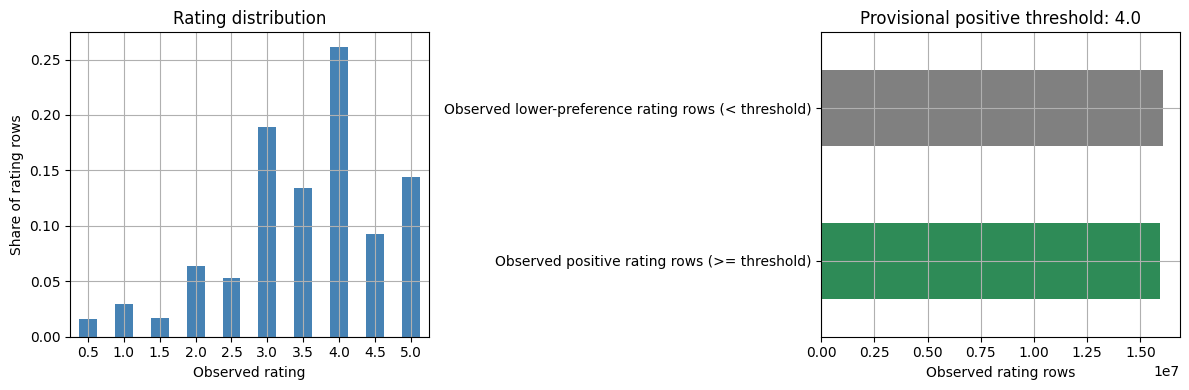

Computed positive ratio: 49.81%; interpret threshold sensitivity before selecting a ranking label.


In [7]:
rating_distribution = ratings['rating'].value_counts(dropna=False).sort_index().to_frame('rating_rows')
rating_distribution['proportion'] = rating_distribution['rating_rows'] / len(ratings)
display(rating_distribution)
display(ratings['rating'].describe(percentiles=[.01, .10, .25, .50, .75, .90, .99]).to_frame('rating'))
label_distribution = pd.Series({
    'Observed positive rating rows (>= threshold)': int(ratings['_positive'].sum()),
    'Observed lower-preference rating rows (< threshold)': int((~ratings['_positive']).sum()),
}).to_frame('rows')
label_distribution['proportion'] = label_distribution['rows'] / len(ratings)
display(label_distribution)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rating_distribution['proportion'].plot.bar(ax=axes[0], rot=0, color='steelblue')
axes[0].set(xlabel='Observed rating', ylabel='Share of rating rows', title='Rating distribution')
label_distribution['rows'].plot.barh(ax=axes[1], color=['seagreen', 'gray'])
axes[1].set(xlabel='Observed rating rows', title=f'Provisional positive threshold: {POSITIVE_THRESHOLD}')
fig.tight_layout()
plt.show()
print(f'Computed positive ratio: {ratings["_positive"].mean():.2%}; '
      'interpret threshold sensitivity before selecting a ranking label.')


## 6. User activity and concentration
**Objective:** measure lifetime history, positive evidence, activity spans, and activity concentration.
These are **full-dataset** user summaries. Only the cutoff-specific counters in Section 12 can establish history available to a prospective model.
Activity span is last minus first observed rating, not continuous membership duration. Distinct active months count months with any observed rating.


,rating_rows,positive_rows,mean_rating,median_rating,first_timestamp,last_timestamp,active_months,span_days,first_utc,last_utc,positive_ratio
userId,,,,,,,,,,,
25062,116,81,3.784483,4.0,789652004,863606381,6,855.953437,1995-01-09 11:46:44+00:00,1997-05-14 10:39:41+00:00,0.698276
30917,62,24,3.435484,3.0,789652009,852810527,2,731.001366,1995-01-09 11:46:49+00:00,1997-01-09 11:48:47+00:00,0.387097
38835,198,116,3.742424,4.0,822873600,850573590,12,320.601736,1996-01-29 00:00:00+00:00,1996-12-14 14:26:30+00:00,0.585859
43720,87,75,4.160920,4.0,822873600,842720195,8,229.705961,1996-01-29 00:00:00+00:00,1996-09-14 16:56:35+00:00,0.862069
65379,81,33,3.296296,3.0,822873600,855528318,4,377.948125,1996-01-29 00:00:00+00:00,1997-02-09 22:45:18+00:00,0.407407


,rating_rows,positive_rows,mean_rating,median_rating,span_days,active_months
entities,200948.000000,200948.000000,200948.000000,200948.000000,200948.000000,200948.000000
mean,159.246193,79.315201,3.704369,3.817930,259.117871,3.700186
std,282.025462,113.054736,0.486565,0.608093,822.072529,11.647141
min,20.000000,0.000000,0.500000,0.500000,0.000000,1.000000
P10,25.000000,13.000000,3.111111,3.000000,0.004838,1.000000
P25,36.000000,21.000000,3.415385,3.500000,0.011227,1.000000
P50 / median,73.000000,42.000000,3.725000,4.000000,0.065289,1.000000
P75,167.000000,92.000000,4.025000,4.000000,53.075446,2.000000
P90,364.000000,183.000000,4.293103,4.500000,708.981725,6.000000
P95,571.000000,268.000000,4.456212,5.000000,1597.841842,13.000000


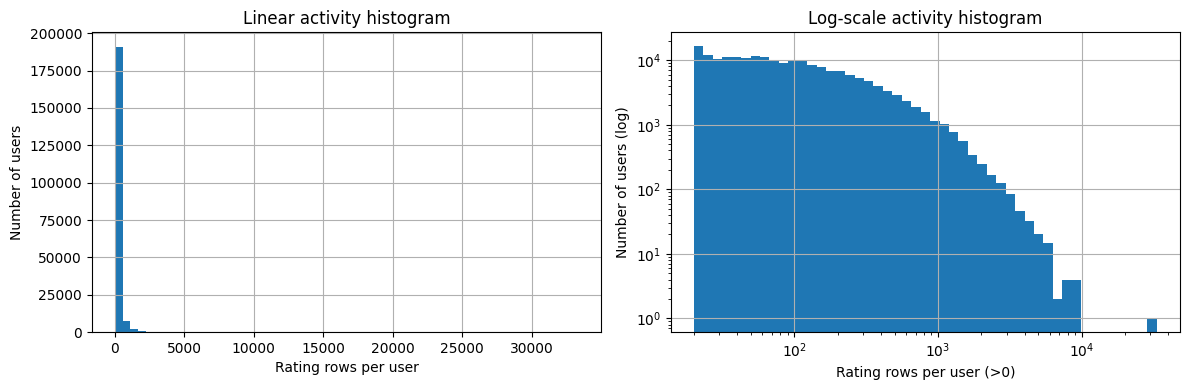

,top_entity_fraction,entity_count,interaction_share
0,0.01,2010,0.125656
1,0.05,10048,0.330173
2,0.10,20095,0.471979
3,0.20,40190,0.643236


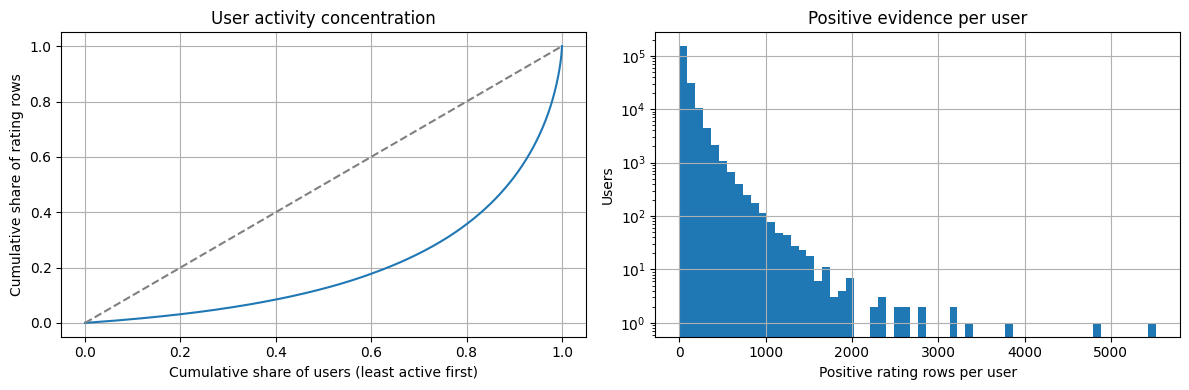

,low activity (<= P25),high activity (>= P75)
rating,,
0.5,0.015134,0.018089
1.0,0.029886,0.030685
1.5,0.010823,0.019589
2.0,0.051668,0.069160
2.5,0.026356,0.063229
3.0,0.192500,0.192049
3.5,0.073292,0.152283
4.0,0.268493,0.253494
4.5,0.086525,0.089355


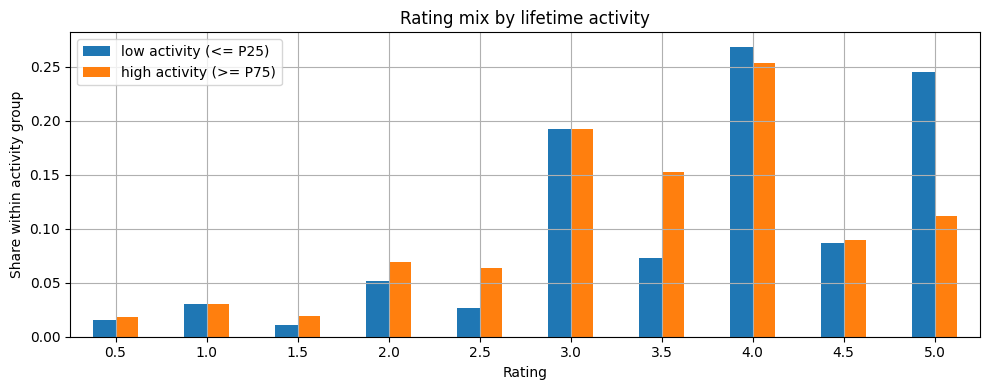

Activity cutoffs: low <= 36; high >= 167. Users in both groups due to ties: 0. These descriptive cohorts use future activity and cannot be used as cutoff-time features.


In [8]:
user_stats = ratings.groupby('userId', sort=False).agg(
    rating_rows=('movieId', 'size'), positive_rows=('_positive', 'sum'),
    mean_rating=('rating', 'mean'), median_rating=('rating', 'median'),
    first_timestamp=('timestamp', 'min'), last_timestamp=('timestamp', 'max'),
    active_months=('_month', 'nunique'))
user_stats['span_days'] = (user_stats['last_timestamp'] - user_stats['first_timestamp']) / 86400
user_stats['first_utc'] = utc_datetimes(user_stats['first_timestamp'])
user_stats['last_utc'] = utc_datetimes(user_stats['last_timestamp'])
user_stats['positive_ratio'] = user_stats['positive_rows'] / user_stats['rating_rows']
display(user_stats.head())
display(pd.DataFrame({column: describe_activity(user_stats[column]) for column in
    ['rating_rows', 'positive_rows', 'mean_rating', 'median_rating', 'span_days', 'active_months']}))
distribution_panels(user_stats['rating_rows'], 'user')
display(concentration(user_stats['rating_rows']))
user_ordered_counts = np.sort(user_stats['rating_rows'].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, len(user_ordered_counts) + 1) / len(user_ordered_counts),
             np.cumsum(user_ordered_counts) / user_ordered_counts.sum())
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[0].set(xlabel='Cumulative share of users (least active first)', ylabel='Cumulative share of rating rows',
            title='User activity concentration')
axes[1].hist(user_stats['positive_rows'], bins=60)
axes[1].set(xlabel='Positive rating rows per user', ylabel='Users', yscale='log', title='Positive evidence per user')
fig.tight_layout()
plt.show()
# Inclusive quartile thresholds can overlap when activity values are tied; disclose overlap.
low_cut, high_cut = user_stats['rating_rows'].quantile([.25, .75])
low_users = user_stats.index[user_stats['rating_rows'] <= low_cut]
high_users = user_stats.index[user_stats['rating_rows'] >= high_cut]
activity_rating_dist = pd.DataFrame({
    'low activity (<= P25)': ratings.loc[ratings['userId'].isin(low_users), 'rating'].value_counts(normalize=True),
    'high activity (>= P75)': ratings.loc[ratings['userId'].isin(high_users), 'rating'].value_counts(normalize=True),
}).sort_index().fillna(0)
display(activity_rating_dist)
activity_rating_dist.plot.bar(rot=0, ylabel='Share within activity group', xlabel='Rating', title='Rating mix by lifetime activity')
plt.tight_layout()
plt.show()
print(f'Activity cutoffs: low <= {low_cut:g}; high >= {high_cut:g}. '
      f'Users in both groups due to ties: {len(low_users.intersection(high_users)):,}. '
      'These descriptive cohorts use future activity and cannot be used as cutoff-time features.')


## 7. Movie activity, supported means, and the long tail
**Objective:** distinguish catalog coverage, interaction popularity, and mean rating with sufficient observed support.
A support threshold is an exploratory filter, not a confidence guarantee or a quality ranking.


Catalog movies with zero rating rows: 3153


,title,genres
movieId,,
52696,"Thousand and One Nights, A (1001 Nights) (1945)",Adventure
58209,Alex in Wonder (Sex and a Girl) (2001),Comedy|Drama
69864,Blue Blood (2006),Documentary
70312,"Family Secret, A (Le secret de ma mère) (2006)",Comedy|Drama|Musical
71355,February (Khumphaphan) (2003),Drama|Romance
78719,Ashes and Blood (2009),Drama
78871,"Genesis Found, A (2010)",Adventure|Mystery
79363,Music in the Air (1934),Comedy|Musical|Romance
79899,Ten9Eight: Shoot for the Moon (2009),Documentary


,rating_rows,positive_rows,distinct_users
entities,87585.000000,87585.000000,87585.000000
mean,365.361694,181.974436,365.361694
std,2546.327582,1603.012498,2546.327582
min,0.000000,0.000000,0.000000
P10,1.000000,0.000000,1.000000
P25,2.000000,0.000000,2.000000
P50 / median,5.000000,1.000000,5.000000
P75,23.000000,6.000000,23.000000
P90,230.000000,76.000000,230.000000
P95,1006.600000,363.800000,1006.600000


,title,rating_rows,distinct_users,mean_rating
movieId,,,,
318,"Shawshank Redemption, The (1994)",102929,102929,4.404614
356,Forrest Gump (1994),100296,100296,4.052744
296,Pulp Fiction (1994),98409,98409,4.196969
2571,"Matrix, The (1999)",93808,93808,4.156436
593,"Silence of the Lambs, The (1991)",90330,90330,4.148367
260,Star Wars: Episode IV - A New Hope (1977),85010,85010,4.099823
2959,Fight Club (1999),77332,77332,4.228780
480,Jurassic Park (1993),75233,75233,3.698623
527,Schindler's List (1993),73849,73849,4.236990


,title,rating_rows,mean_rating,positive_ratio
movieId,,,,
171011,Planet Earth II (2016),1956,4.446830,0.890082
159817,Planet Earth (2006),2948,4.444369,0.880258
170705,Band of Brothers (2001),2811,4.426538,0.871220
318,"Shawshank Redemption, The (1994)",102929,4.404614,0.862274
171495,Cosmos,615,4.330081,0.832520
858,"Godfather, The (1972)",66440,4.317030,0.823992
202439,Parasite (2019),11670,4.312253,0.833333
179135,Blue Planet II (2017),1163,4.300086,0.830610
198185,Twin Peaks (1989),1140,4.298684,0.820175


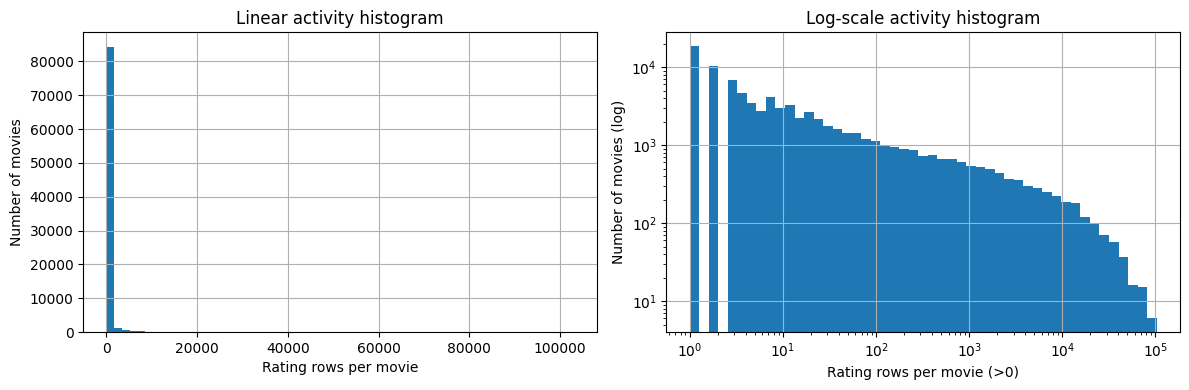

,top_entity_fraction,entity_count,interaction_share
0,0.01,876,0.557567
1,0.05,4380,0.890970
2,0.10,8759,0.959400
3,0.20,17517,0.986375


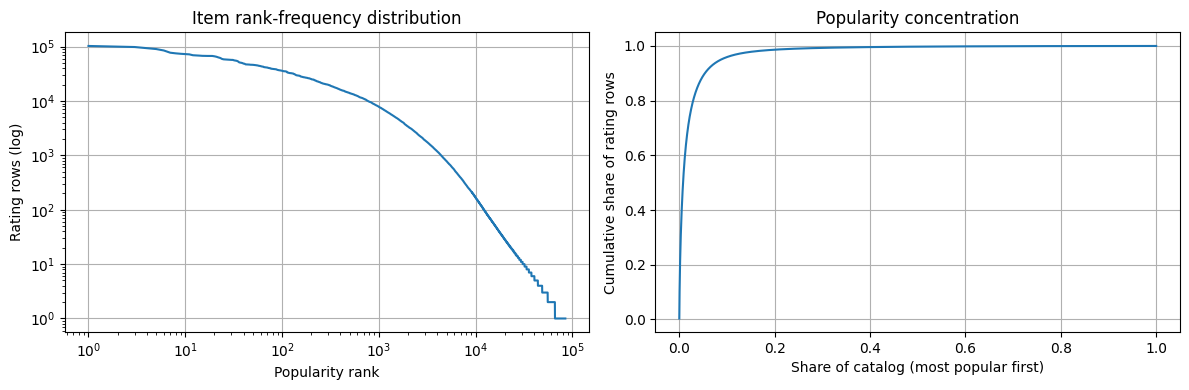

,max_rating_rows,catalog_movies,catalog_share,rating_row_share
0,0,3153,0.035999,0.000000
1,1,21760,0.248444,0.000581
2,5,47180,0.538677,0.003004
3,10,57064,0.651527,0.005372
4,20,64727,0.739019,0.008879
5,100,75440,0.861335,0.024246


Interpretation: compare supported mean ratings with frequency rankings. Tail catalog coverage and tail interaction share answer different questions; neither measures recommendation coverage.


In [9]:
observed_item_stats = ratings.groupby('movieId', sort=False).agg(
    rating_rows=('userId', 'size'), positive_rows=('_positive', 'sum'),
    distinct_users=('userId', 'nunique'), mean_rating=('rating', 'mean'),
    first_timestamp=('timestamp', 'min'), last_timestamp=('timestamp', 'max'))
item_stats = movies.set_index('movieId').join(observed_item_stats, how='left', validate='one_to_one')
for column in ('rating_rows', 'positive_rows', 'distinct_users'):
    item_stats[column] = item_stats[column].fillna(0).astype('int64')
item_stats['positive_ratio'] = item_stats['positive_rows'] / item_stats['rating_rows'].replace(0, np.nan)
zero_rating_movies = item_stats.loc[item_stats['rating_rows'].eq(0), ['title', 'genres']]
print('Catalog movies with zero rating rows:', len(zero_rating_movies))
display(zero_rating_movies.head(20))
display(pd.DataFrame({column: describe_activity(item_stats[column]) for column in
                     ['rating_rows', 'positive_rows', 'distinct_users']}))
display(item_stats.nlargest(20, 'rating_rows')[['title', 'rating_rows', 'distinct_users', 'mean_rating']])
display(item_stats.loc[item_stats['rating_rows'] >= MIN_ITEM_SUPPORT].nlargest(20, 'mean_rating')
        [['title', 'rating_rows', 'mean_rating', 'positive_ratio']])
distribution_panels(item_stats['rating_rows'], 'movie')
display(concentration(item_stats['rating_rows']))
popularity = np.sort(item_stats['rating_rows'].to_numpy())[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nonzero = popularity > 0
axes[0].loglog(np.arange(1, nonzero.sum() + 1), popularity[nonzero])
axes[0].set(xlabel='Popularity rank', ylabel='Rating rows (log)', title='Item rank-frequency distribution')
axes[1].plot(np.arange(1, len(popularity) + 1) / len(popularity), np.cumsum(popularity) / popularity.sum())
axes[1].set(xlabel='Share of catalog (most popular first)', ylabel='Cumulative share of rating rows',
            title='Popularity concentration')
fig.tight_layout()
plt.show()
tail_coverage = pd.DataFrame([
    {'max_rating_rows': limit, 'catalog_movies': int((item_stats['rating_rows'] <= limit).sum()),
     'catalog_share': (item_stats['rating_rows'] <= limit).mean(),
     'rating_row_share': item_stats.loc[item_stats['rating_rows'] <= limit, 'rating_rows'].sum() / len(ratings)}
    for limit in [0, 1, 5, 10, 20, 100]
])
display(tail_coverage)
print('Interpretation: compare supported mean ratings with frequency rankings. Tail catalog coverage '
      'and tail interaction share answer different questions; neither measures recommendation coverage.')


## 8. Temporal EDA
**Objective:** inspect volume, positives, first-seen entities, returning activity, and monthly density before evaluating temporal windows.
The first/last calendar months are usually partial observations; sharp changes may reflect dataset collection or user selection.
A movie's first observed rating is **not** its release date or verified catalog availability date.
Monthly density uses distinct observed pairs / (monthly active users × monthly active movies), not the full catalog denominator.


,rating_rows,positive_rows,mean_rating,active_users,active_movies,positive_ratio
year,,,,,,
1995,4,2,3.750000,2,4,0.500000
1996,1571368,768503,3.546181,25305,1386,0.489066
1997,685388,354793,3.588809,11073,1673,0.517653
1998,301691,164372,3.514003,3662,2302,0.544836
1999,1174629,693357,3.616688,9227,3038,0.590277
2000,1912322,1098074,3.576486,14668,3876,0.574210
2001,1160098,644495,3.533513,10224,4728,0.555552
2002,849762,456259,3.484735,7788,5737,0.536926
2003,1011000,486619,3.473930,8406,6818,0.481324


,rating_rows,positive_rows,active_users,active_movies,mean_rating,positive_ratio,first_seen_users,first_seen_movies,returning_users,returning_user_rating_rows,unique_pairs,active_matrix_density,rating_rows_per_active_user,month_start_utc
_month,,,,,,,,,,,,,,
24262,73419,35491,2794,10960,3.545622,0.483403,344,532,2450,29201,73419,0.002398,26.277380,2021-11-01 00:00:00+00:00
24263,87357,42320,2908,15104,3.544461,0.484449,348,884,2560,39181,87357,0.001989,30.040234,2021-12-01 00:00:00+00:00
24264,105045,47558,3069,14633,3.458408,0.452739,432,649,2637,38325,105045,0.002339,34.227761,2022-01-01 00:00:00+00:00
24265,89586,39836,2696,14562,3.438339,0.444668,347,613,2349,34261,89586,0.002282,33.229228,2022-02-01 00:00:00+00:00
24266,73954,33931,2630,12444,3.493577,0.458812,308,649,2322,27841,73954,0.002260,28.119392,2022-03-01 00:00:00+00:00
24267,78431,37751,2653,12406,3.543694,0.481328,375,507,2278,30920,78431,0.002383,29.563136,2022-04-01 00:00:00+00:00
24268,64867,30788,2534,11106,3.512772,0.474633,284,391,2250,30860,64867,0.002305,25.598658,2022-05-01 00:00:00+00:00
24269,70348,33533,2478,11569,3.515580,0.476673,306,428,2172,26565,70348,0.002454,28.389023,2022-06-01 00:00:00+00:00
24270,62898,30021,2564,10436,3.494586,0.477297,303,390,2261,29293,62898,0.002351,24.531201,2022-07-01 00:00:00+00:00


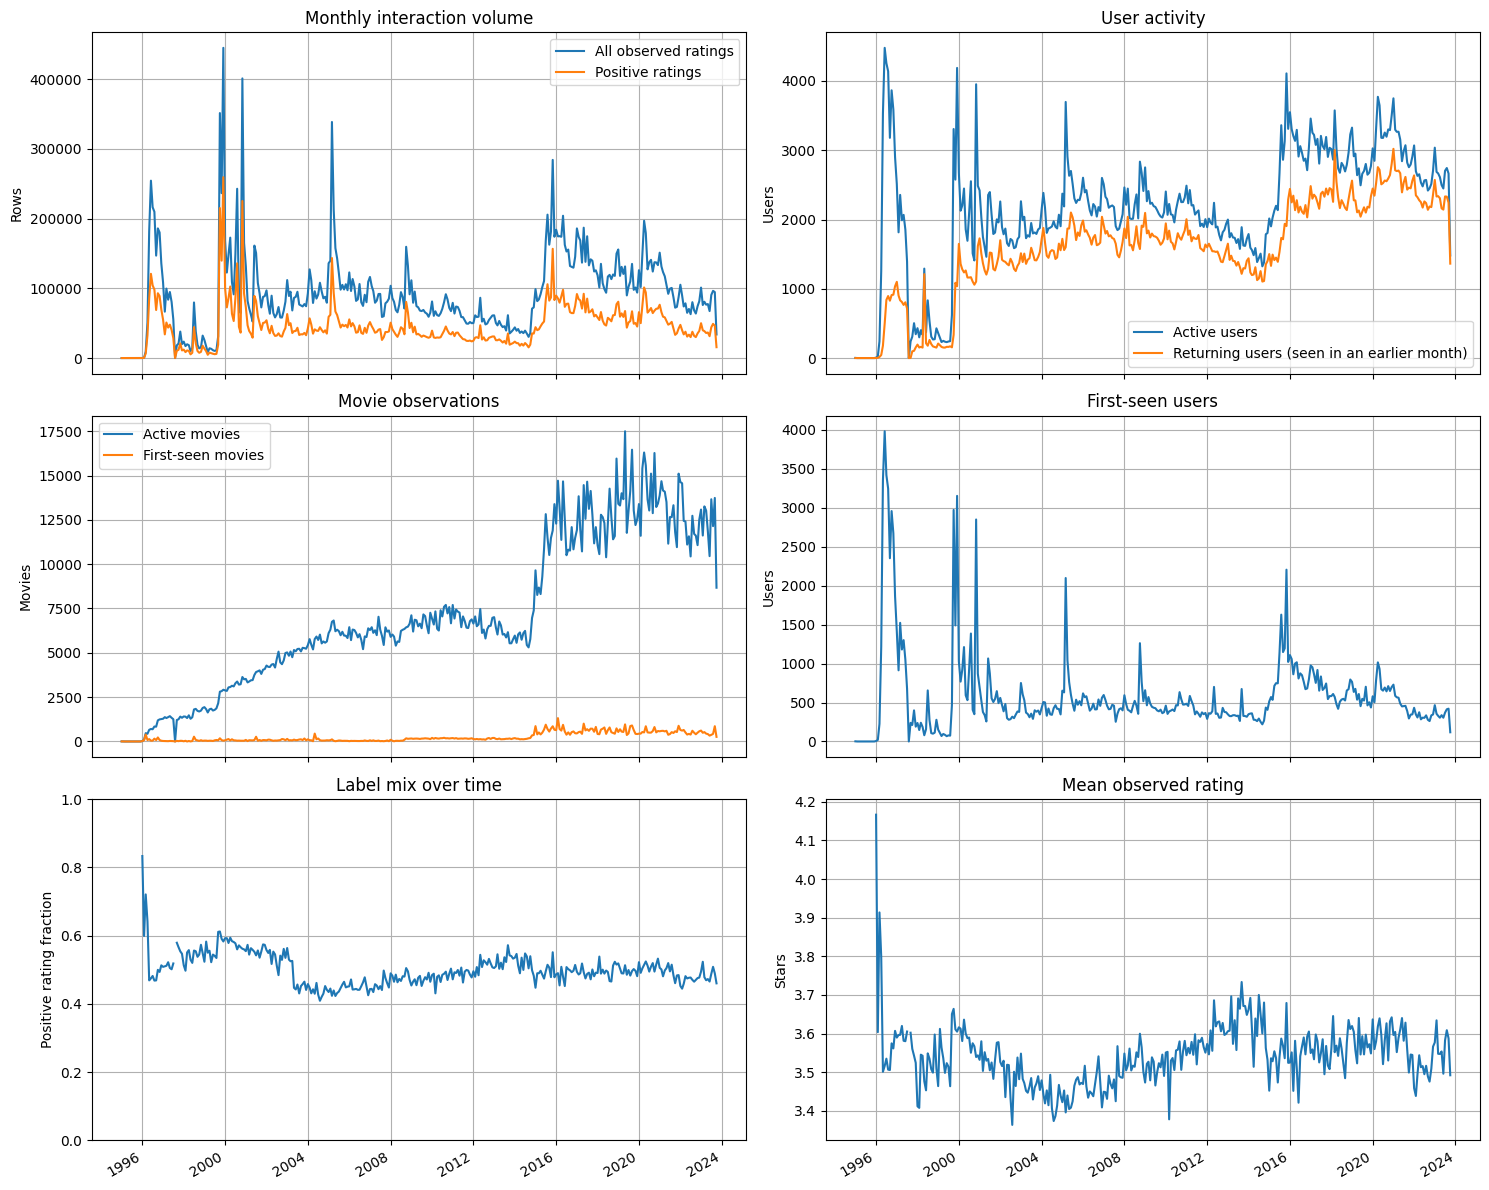

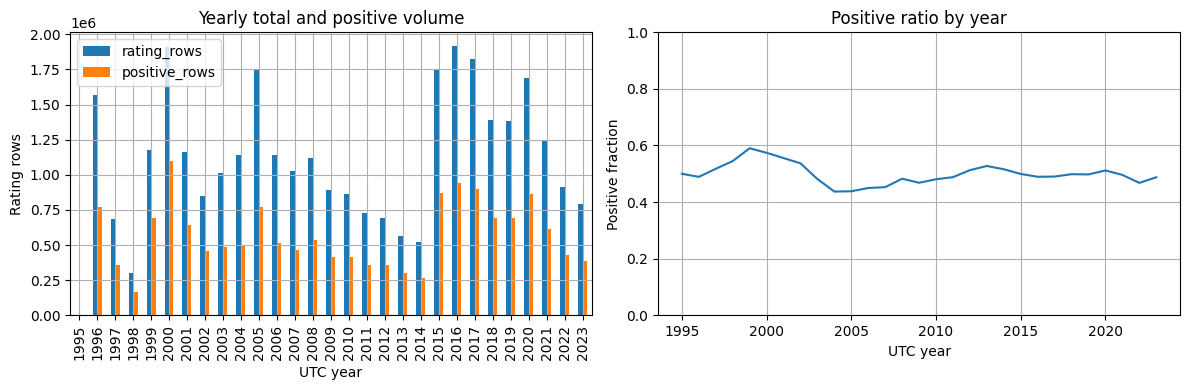

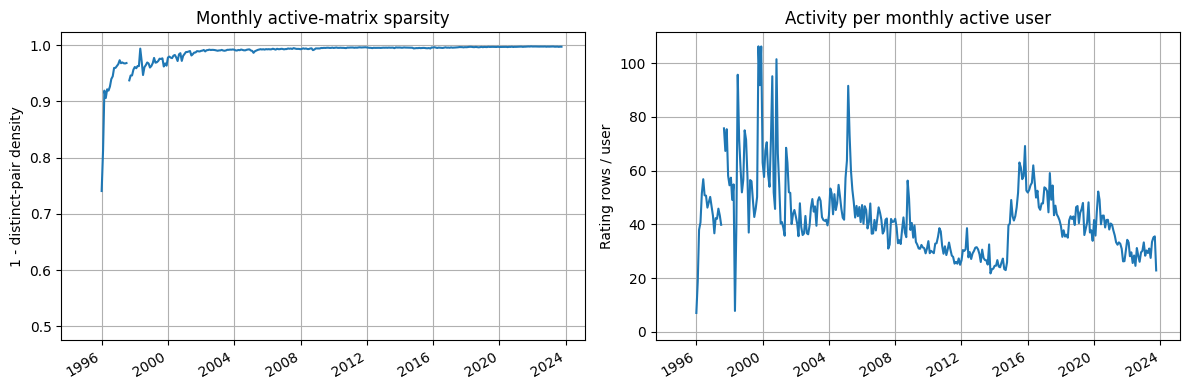

,lookback_years,start_utc,rating_rows,share_of_all_rows
0,1,2022-10-13 02:29:07+00:00,988745,0.030898
1,3,2020-10-13 02:29:07+00:00,3302471,0.103202
2,5,2018-10-13 02:29:07+00:00,6362637,0.198831


,rating_rows,month_over_month_change,abs_change
_month,,,
23954,9184,19.454343,19.454343
23997,351183,10.217395,10.217395
23953,449,9.690476,9.690476
24010,400851,5.222945,5.222945
23955,51197,4.574586,4.574586
23982,79681,4.498275,4.498275
23956,181762,2.550247,2.550247
24017,161172,2.083510,2.083510
23996,31307,1.804784,1.804784


Interpretation: inspect the largest month-to-month changes, partial endpoint months, recent positive counts, and recurring users together. Section 12 tests whether observed histories support actual prospective windows.


In [10]:
monthly = ratings.groupby('_month', sort=True).agg(
    rating_rows=('rating', 'size'), positive_rows=('_positive', 'sum'),
    active_users=('userId', 'nunique'), active_movies=('movieId', 'nunique'), mean_rating=('rating', 'mean'))
monthly = monthly.reindex(range(int(ratings['_month'].min()), int(ratings['_month'].max()) + 1))
for column in ['rating_rows', 'positive_rows', 'active_users', 'active_movies']:
    monthly[column] = monthly[column].fillna(0).astype('int64')
monthly['positive_ratio'] = monthly['positive_rows'] / monthly['rating_rows'].replace(0, np.nan)
first_user_month = ratings.groupby('userId', sort=False)['_month'].min()
first_item_month = ratings.groupby('movieId', sort=False)['_month'].min()
monthly['first_seen_users'] = first_user_month.value_counts().reindex(monthly.index, fill_value=0)
monthly['first_seen_movies'] = first_item_month.value_counts().reindex(monthly.index, fill_value=0)
monthly['returning_users'] = monthly['active_users'] - monthly['first_seen_users']
is_returning = ratings['_month'].gt(ratings['userId'].map(first_user_month))
monthly['returning_user_rating_rows'] = is_returning.groupby(ratings['_month']).sum().reindex(monthly.index, fill_value=0)
del is_returning
if duplicate_pairs == 0:
    monthly['unique_pairs'] = monthly['rating_rows']
else:
    # Deduplicate only a temporary projection for a distinct-pair statistic, not source observations.
    month_pairs = ratings[['userId', 'movieId', '_month']].drop_duplicates()
    monthly['unique_pairs'] = month_pairs.groupby('_month').size().reindex(monthly.index, fill_value=0)
    del month_pairs
monthly['active_matrix_density'] = monthly['unique_pairs'] / (
    monthly['active_users'] * monthly['active_movies']).replace(0, np.nan)
monthly['rating_rows_per_active_user'] = monthly['rating_rows'] / monthly['active_users'].replace(0, np.nan)
monthly['month_start_utc'] = month_labels(monthly.index).to_numpy()
year_code = ratings['_month'] // 12
yearly = ratings.groupby(year_code).agg(rating_rows=('rating', 'size'), positive_rows=('_positive', 'sum'),
    mean_rating=('rating', 'mean'), active_users=('userId', 'nunique'), active_movies=('movieId', 'nunique'))
yearly.index.name = 'year'
yearly['positive_ratio'] = yearly['positive_rows'] / yearly['rating_rows']
display(yearly)
display(monthly.tail(24))
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
x = pd.DatetimeIndex(monthly['month_start_utc'])
for column, label in [('rating_rows', 'All observed ratings'), ('positive_rows', 'Positive ratings')]:
    axes[0, 0].plot(x, monthly[column], label=label)
axes[0, 0].set(title='Monthly interaction volume', ylabel='Rows')
axes[0, 0].legend()
axes[0, 1].plot(x, monthly['active_users'], label='Active users')
axes[0, 1].plot(x, monthly['returning_users'], label='Returning users (seen in an earlier month)')
axes[0, 1].legend()
axes[0, 1].set(title='User activity', ylabel='Users')
axes[1, 0].plot(x, monthly['active_movies'], label='Active movies')
axes[1, 0].plot(x, monthly['first_seen_movies'], label='First-seen movies')
axes[1, 0].legend()
axes[1, 0].set(title='Movie observations', ylabel='Movies')
axes[1, 1].plot(x, monthly['first_seen_users'])
axes[1, 1].set(title='First-seen users', ylabel='Users')
axes[2, 0].plot(x, monthly['positive_ratio'], label='Positive ratio')
axes[2, 0].set(title='Label mix over time', ylabel='Positive rating fraction', ylim=(0, 1))
axes[2, 1].plot(x, monthly['mean_rating'])
axes[2, 1].set(title='Mean observed rating', ylabel='Stars')
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yearly[['rating_rows', 'positive_rows']].plot.bar(ax=axes[0])
axes[0].set(xlabel='UTC year', ylabel='Rating rows', title='Yearly total and positive volume')
yearly[['positive_ratio']].plot(ax=axes[1], legend=False)
axes[1].set(xlabel='UTC year', ylabel='Positive fraction', title='Positive ratio by year', ylim=(0, 1))
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, 1 - monthly['active_matrix_density'])
axes[0].set(title='Monthly active-matrix sparsity', ylabel='1 - distinct-pair density')
axes[1].plot(x, monthly['rating_rows_per_active_user'])
axes[1].set(title='Activity per monthly active user', ylabel='Rating rows / user')
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
last_time_utc = pd.to_datetime(int(ratings['timestamp'].iloc[-1]), unit='s', utc=True)
recent_volume = pd.DataFrame([
    {'lookback_years': years, 'start_utc': last_time_utc - pd.DateOffset(years=years),
     'rating_rows': int((ratings['timestamp'] >= int((last_time_utc - pd.DateOffset(years=years)).timestamp())).sum())}
    for years in [1, 3, 5]
])
recent_volume['share_of_all_rows'] = recent_volume['rating_rows'] / len(ratings)
display(recent_volume)
volume_change = monthly['rating_rows'].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
display(pd.DataFrame({'rating_rows': monthly['rating_rows'], 'month_over_month_change': volume_change})
        .assign(abs_change=volume_change.abs()).nlargest(12, 'abs_change'))
print('Interpretation: inspect the largest month-to-month changes, partial endpoint months, recent positive counts, '
      'and recurring users together. Section 12 tests whether observed histories support actual prospective windows.')


## 9. Genres and user genre profiles
**Objective:** quantify overlapping metadata coverage and observed preferences without exploding 32M ratings into genre rows.
Movie–genre memberships may overlap. Catalog frequency is movie membership count; interaction totals below are
rating–genre memberships and can exceed total ratings. Positive rates and means are within each genre's observed ratings.
A small user × genre aggregate is built genre by genre; no dense user × movie matrix is constructed.
Unspecified, malformed, and repeated tokens are reported by the audit and excluded only from this named-genre membership view.


Distinct recognized genres: 19
Movies without recognized genre membership: 7080


,Recognized genres per catalog movie
entities,87585.000000
mean,1.679397
std,1.042744
min,0.000000
P10,1.000000
P25,1.000000
P50 / median,1.000000
P75,2.000000
P90,3.000000
P95,4.000000


,movie_memberships,rating_memberships,positive_memberships,rating_sum,catalog_membership_rate,positive_ratio,mean_rating
genre,,,,,,,
Drama,34175,13973271,7767984,5.145593e+07,0.390192,0.555917,3.682454
Comedy,23124,11206926,5087919,3.846649e+07,0.264018,0.453998,3.432386
Action,9668,9665213,4514423,3.360022e+07,0.110384,0.467080,3.476407
Thriller,11823,8679464,4242532,3.065328e+07,0.134989,0.488801,3.531702
Adventure,5402,7590522,3704655,2.674474e+07,0.061677,0.488063,3.523439
Sci-Fi,4907,5717337,2724764,1.996322e+07,0.056026,0.476579,3.491699
Romance,10369,5524615,2759311,1.958478e+07,0.118388,0.499458,3.545003
Crime,6976,5373051,3006682,1.983607e+07,0.079648,0.559586,3.691771
Fantasy,3851,3702759,1797234,1.300474e+07,0.043969,0.485377,3.512175


,Movies per raw genre combination
genres,
Drama,12443
Documentary,8132
Comedy,7761
(no genres listed),7080
Comedy|Drama,3245
Drama|Romance,2825
Horror,2487
Comedy|Romance,2229
Thriller,1410


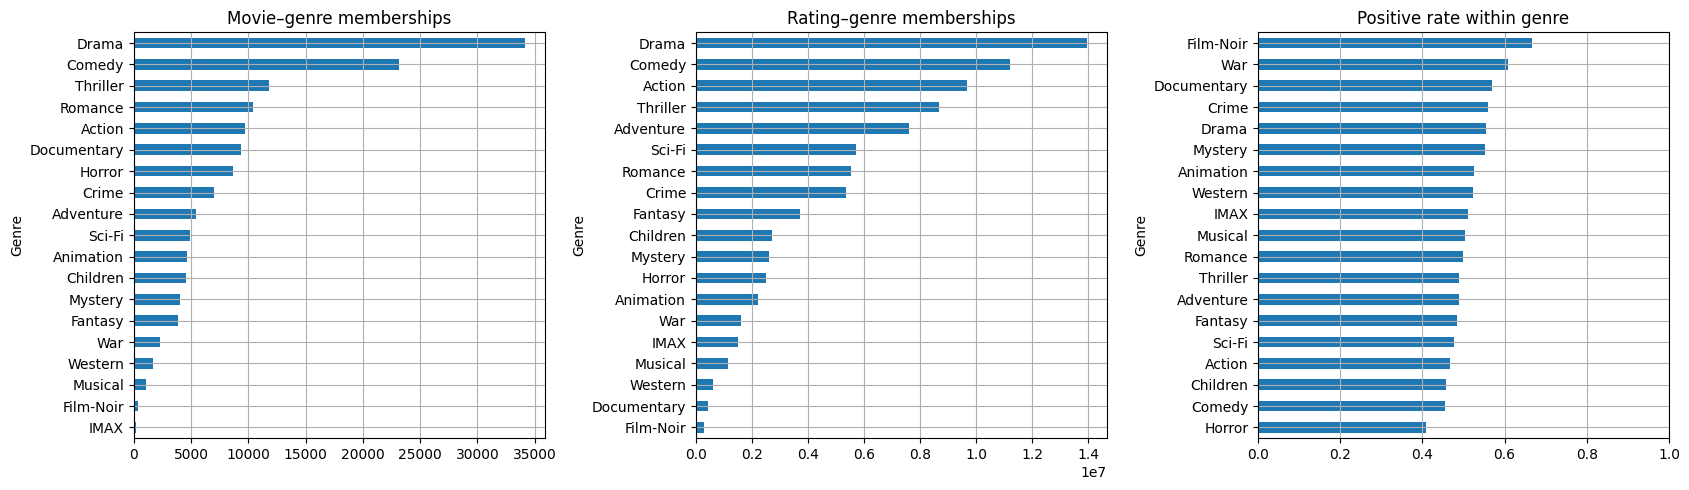

,mean_user_membership_share,10%,50%,90%
genre,,,,
Action,0.110877,0.052083,0.110092,0.168450
Adventure,0.090046,0.044586,0.088086,0.137143
Animation,0.024384,0.000000,0.019108,0.051546
Children,0.031059,0.003386,0.025882,0.062500
Comedy,0.125325,0.060000,0.119565,0.194454
Crime,0.065347,0.028571,0.062500,0.104762
Documentary,0.003296,0.000000,0.000000,0.009881
Drama,0.163686,0.089041,0.155172,0.249029
Fantasy,0.040795,0.014925,0.038202,0.069307


,mean,10%,50%,90%
Action,0.532013,0.200000,0.533333,0.866667
Adventure,0.543633,0.200000,0.545455,0.884615
Animation,0.562415,0.000000,0.600000,1.000000
Children,0.508205,0.000000,0.500000,1.000000
Comedy,0.534447,0.218750,0.533333,0.857143
Crime,0.622408,0.277778,0.645161,1.000000
Documentary,0.614312,0.000000,0.727273,1.000000
Drama,0.625828,0.333333,0.642857,0.894737
Fantasy,0.544589,0.105263,0.542373,1.000000
Film-Noir,0.658721,0.000000,0.846154,1.000000


,Users by dominant observed membership share
Drama,97104
Comedy,41034
Action,36770
Adventure,9562
Thriller,9139
Sci-Fi,3064
Horror,1280
Romance,1092
Children,572
Animation,547


Interpretation: dominant-genre ties follow column order; these are descriptive overlapping profiles, not causal tastes or features safe to compute using future observations.


6457

In [11]:
genre_memberships = movies[['movieId', 'genres']].copy()
genre_memberships['genre'] = genre_memberships['genres'].str.split('|', regex=False)
genre_memberships = genre_memberships.explode('genre')
genre_memberships['genre'] = genre_memberships['genre'].str.strip()
genre_memberships = genre_memberships.loc[genre_memberships['genre'].isin(KNOWN_GENRES), ['movieId', 'genre']]
genre_memberships = genre_memberships.drop_duplicates(['movieId', 'genre'])
genres_per_movie = genre_memberships.groupby('movieId').size().reindex(item_stats.index, fill_value=0)
genre_join = genre_memberships.join(item_stats[['rating_rows', 'positive_rows', 'mean_rating']], on='movieId', validate='many_to_one')
genre_join['rating_sum'] = genre_join['mean_rating'].fillna(0) * genre_join['rating_rows']
genre_stats = genre_join.groupby('genre').agg(movie_memberships=('movieId', 'size'),
    rating_memberships=('rating_rows', 'sum'), positive_memberships=('positive_rows', 'sum'), rating_sum=('rating_sum', 'sum'))
genre_stats['catalog_membership_rate'] = genre_stats['movie_memberships'] / len(movies)
genre_stats['positive_ratio'] = genre_stats['positive_memberships'] / genre_stats['rating_memberships'].replace(0, np.nan)
genre_stats['mean_rating'] = genre_stats['rating_sum'] / genre_stats['rating_memberships'].replace(0, np.nan)
print('Distinct recognized genres:', genre_memberships['genre'].nunique())
print('Movies without recognized genre membership:', int(genres_per_movie.eq(0).sum()))
display(describe_activity(genres_per_movie).to_frame('Recognized genres per catalog movie'))
display(genre_stats.sort_values('rating_memberships', ascending=False))
display(movies['genres'].fillna('<missing>').value_counts().head(20).to_frame('Movies per raw genre combination'))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
genre_stats['movie_memberships'].sort_values().plot.barh(ax=axes[0], title='Movie–genre memberships')
genre_stats['rating_memberships'].sort_values().plot.barh(ax=axes[1], title='Rating–genre memberships')
genre_stats['positive_ratio'].sort_values().plot.barh(ax=axes[2], title='Positive rate within genre', xlim=(0, 1))
for ax in axes:
    ax.set_ylabel('Genre')
fig.tight_layout()
plt.show()
user_genre_counts = pd.DataFrame(index=user_stats.index)
user_genre_positive = pd.DataFrame(index=user_stats.index)
for genre, membership in genre_memberships.groupby('genre', sort=True):
    mask = ratings['movieId'].isin(membership['movieId'])
    counts = ratings.loc[mask, 'userId'].value_counts()
    positive_counts = ratings.loc[mask & ratings['_positive'], 'userId'].value_counts()
    user_genre_counts[genre] = counts.reindex(user_stats.index, fill_value=0).astype('int32')
    user_genre_positive[genre] = positive_counts.reindex(user_stats.index, fill_value=0).astype('int32')
# Denominator is each user's overlapping genre memberships, not that user's raw rating count.
user_genre_share = user_genre_counts.div(user_genre_counts.sum(axis=1).replace(0, np.nan), axis=0)
user_genre_positive_rate = user_genre_positive.div(user_genre_counts.replace(0, np.nan))
display(user_genre_share.describe(percentiles=[.1, .5, .9]).T[['mean', '10%', '50%', '90%']]
        .rename_axis('genre').rename(columns={'mean': 'mean_user_membership_share'}))
display(user_genre_positive_rate.describe(percentiles=[.1, .5, .9]).T[['mean', '10%', '50%', '90%']])
top_user_genre = user_genre_share.loc[user_genre_share.notna().any(axis=1)].idxmax(axis=1)
display(top_user_genre.value_counts().to_frame('Users by dominant observed membership share'))
print('Interpretation: dominant-genre ties follow column order; these are descriptive overlapping profiles, '
      'not causal tastes or features safe to compute using future observations.')
del genre_join, user_genre_counts, user_genre_positive, user_genre_share, user_genre_positive_rate
gc.collect()


## 10. User-generated tags
**Objective:** characterize tag applications separately from ratings. Normalization creates an analytical view only:
Unicode casefolding, trimming, and collapsing whitespace; missing and blank applications remain in source counts.
Tag application frequency is not distinct-user frequency or a rating label.
Aggregating future tags into historical features would leak future information; any later tag features must obey each training cutoff.


,value
tag_application_rows,2.000072e+06
missing_tag_text,0.000000e+00
blank_tag_text,6.000000e+00
distinct_tagging_users,1.584800e+04
distinct_tagged_movie_ids_including_outside_catalog,5.132300e+04
catalog_movies_with_any_tag_application,5.132300e+04
catalog_fraction_with_tag_application,5.859793e-01
invalid_tag_timestamps_excluded_from_time_plot,0.000000e+00


,Normalized tag applications
tag,
sci-fi,11457
atmospheric,10088
action,9344
comedy,9275
funny,8088
surreal,7480
visually appealing,7253
based on a book,6734
twist ending,6600


,Tag applications per catalog movie
entities,87585.000000
mean,22.835782
std,124.680894
min,0.000000
P10,0.000000
P25,0.000000
P50 / median,1.000000
P75,7.000000
P90,30.000000
P95,85.000000


,Original text length (characters)
count,2000072.0
mean,11.110225
std,5.718185
min,1.0
50%,10.0
90%,18.0
99%,29.0
max,241.0


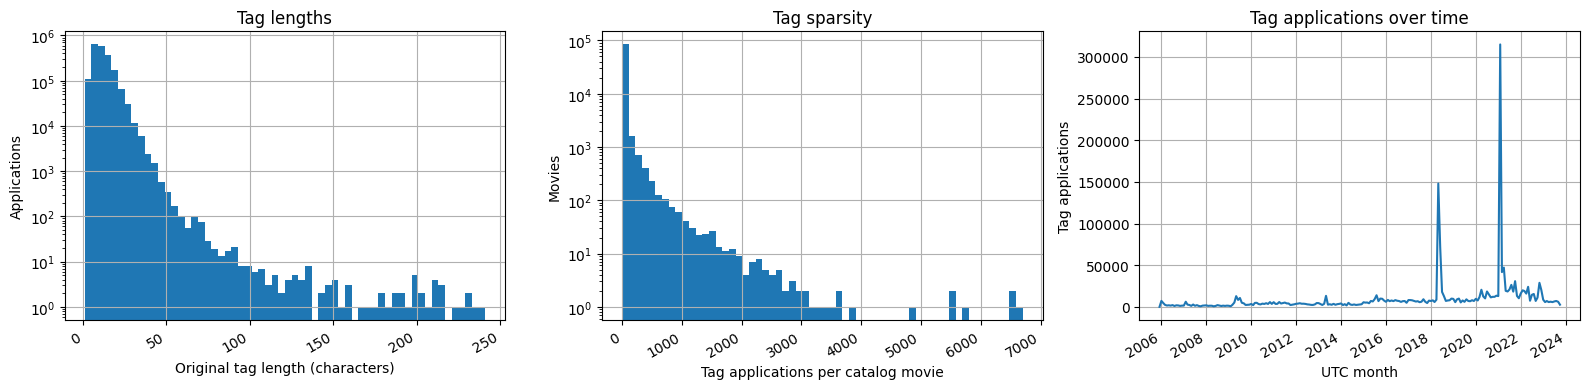

Interpretation: compare tag coverage with the complete catalog. Missing external IDs or absent tags must not be confused with missing rating interactions. No external metadata is fetched.


1882

In [12]:
normalized_tags = tags['tag'].str.casefold().str.strip().str.replace(r'\s+', ' ', regex=True)
valid_tag_text = normalized_tags.notna() & normalized_tags.ne('')
tag_lengths = tags['tag'].str.len()
tag_apps_per_movie = tags.groupby('movieId', dropna=False).size().reindex(item_stats.index, fill_value=0)
tag_utc = utc_datetimes(tags['timestamp'])
valid_tag_time = ~timestamp_bad_mask(tags['timestamp'])
tag_month = (tag_utc.loc[valid_tag_time].dt.year * 12 + tag_utc.loc[valid_tag_time].dt.month - 1).astype('int32')
tag_monthly = tag_month.value_counts().sort_index()
tag_summary = pd.Series({
    'tag_application_rows': len(tags), 'missing_tag_text': int(tags['tag'].isna().sum()),
    'blank_tag_text': int(blank_mask(tags['tag']).sum()), 'distinct_tagging_users': tags['userId'].nunique(),
    'distinct_tagged_movie_ids_including_outside_catalog': tags['movieId'].nunique(),
    'catalog_movies_with_any_tag_application': int(tag_apps_per_movie.gt(0).sum()),
    'catalog_fraction_with_tag_application': tag_apps_per_movie.gt(0).mean(),
    'invalid_tag_timestamps_excluded_from_time_plot': int((~valid_tag_time).sum()),
})
display(tag_summary.to_frame('value'))
display(normalized_tags.loc[valid_tag_text].value_counts().head(30).to_frame('Normalized tag applications'))
display(describe_activity(tag_apps_per_movie).to_frame('Tag applications per catalog movie'))
display(tag_lengths.describe(percentiles=[.5, .9, .99]).to_frame('Original text length (characters)'))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(tag_lengths.dropna(), bins=60)
axes[0].set(xlabel='Original tag length (characters)', ylabel='Applications', yscale='log', title='Tag lengths')
axes[1].hist(tag_apps_per_movie, bins=60)
axes[1].set(xlabel='Tag applications per catalog movie', ylabel='Movies', yscale='log', title='Tag sparsity')
axes[2].plot(month_labels(tag_monthly.index), tag_monthly.to_numpy())
axes[2].set(xlabel='UTC month', ylabel='Tag applications', title='Tag applications over time')
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print('Interpretation: compare tag coverage with the complete catalog. Missing external IDs or absent tags '
      'must not be confused with missing rating interactions. No external metadata is fetched.')
del normalized_tags, valid_tag_text, tag_lengths, tag_utc, valid_tag_time, tag_month
gc.collect()


## 11. Interaction matrix size and representation costs
**Objective:** estimate storage from distinct user–movie pairs, without constructing a matrix.
CSR estimates include values, column indices, and row pointers only; Python objects, conversions, factor matrices,
training state, and framework overhead are excluded. Positive-only pairs are deduplicated separately if necessary.
Full catalog density includes zero-rating items. Rated-item density uses only observed movies.


In [13]:
n_users = ratings['userId'].nunique()
n_catalog = len(movies)
n_rated_items = ratings['movieId'].nunique()
n_unique_pairs = len(ratings) - duplicate_pairs
if duplicate_pairs:
    positive_unique_pairs = len(ratings.loc[ratings['_positive'], ['userId', 'movieId']].drop_duplicates())
else:
    positive_unique_pairs = int(ratings['_positive'].sum())
matrix_summary = pd.Series({
    'unique_rating_users': n_users, 'catalog_movies': n_catalog, 'rated_movies': n_rated_items,
    'unique_user_movie_pairs': n_unique_pairs, 'positive_unique_pairs': positive_unique_pairs,
    'all_observed_pair_catalog_density': n_unique_pairs / (n_users * n_catalog),
    'all_observed_pair_catalog_sparsity': 1 - n_unique_pairs / (n_users * n_catalog),
    'all_observed_pair_rated_item_density': n_unique_pairs / (n_users * n_rated_items),
    'positive_pair_catalog_density': positive_unique_pairs / (n_users * n_catalog),
})
display(matrix_summary.to_frame('value'))
representation_rows = []
for value_dtype in ('bool', 'float32', 'float64'):
    value_bytes = np.dtype(value_dtype).itemsize
    representation_rows.append({'representation': f'dense {value_dtype}', 'pair_definition': 'full catalog grid',
        'estimated_GiB': n_users * n_catalog * value_bytes / 2**30, 'index_dtype': 'none'})
    for index_dtype in ('int32', 'int64'):
        index_bytes = np.dtype(index_dtype).itemsize
        for pair_definition, nnz in [('all observed pairs', n_unique_pairs), ('positive pairs', positive_unique_pairs)]:
            safe_indices = max(nnz, n_users + 1, n_catalog) <= np.iinfo(index_dtype).max
            representation_rows.append({'representation': f'CSR {value_dtype}', 'pair_definition': pair_definition,
                'estimated_GiB': (nnz * (value_bytes + index_bytes) + (n_users + 1) * index_bytes) / 2**30,
                'index_dtype': index_dtype, 'index_range_safe': safe_indices})
representation_memory = pd.DataFrame(representation_rows)
display(representation_memory)


,value
unique_rating_users,2.009480e+05
catalog_movies,8.758500e+04
rated_movies,8.443200e+04
unique_user_movie_pairs,3.200020e+07
positive_unique_pairs,1.593823e+07
all_observed_pair_catalog_density,1.818190e-03
all_observed_pair_catalog_sparsity,9.981818e-01
all_observed_pair_rated_item_density,1.886088e-03
positive_pair_catalog_density,9.055797e-04


,representation,pair_definition,estimated_GiB,index_dtype,index_range_safe
0,dense bool,full catalog grid,16.391306,none,NaN
1,CSR bool,all observed pairs,0.149761,int32,True
2,CSR bool,positive pairs,0.074967,int32,True
3,CSR bool,all observed pairs,0.269720,int64,True
4,CSR bool,positive pairs,0.135090,int64,True
5,dense float32,full catalog grid,65.565223,none,NaN
6,CSR float32,all observed pairs,0.239169,int32,True
7,CSR float32,positive pairs,0.119498,int32,True
8,CSR float32,all observed pairs,0.359127,int64,True
9,CSR float32,positive pairs,0.179621,int64,True


**Interpretation for planned retrieval channels:** ItemCF must avoid a dense item × item similarity matrix and later bound neighbor computation.
Implicit ALS can use sparse positive/confidence inputs, with preference/confidence semantics approved separately; explicit low ratings are not missing data.
LightGCN needs sparse bipartite edges and additional memory for reverse edges, embeddings, and optimization state.
Two-Tower requires timestamp-safe examples and sampling; sampled unobserved items are training assumptions, not verified dislikes.
Popularity and genre retrieval also require cutoff-specific statistics. No channel is implemented here.

## 12. Global temporal split feasibility
**Objective:** compare four fixed-row targets and three calendar lookbacks using strictly prior history.
These calculations inspect windows only: no train/test DataFrames or split files are created.

**Boundary policy:** for a row target, find the timestamp of the nominal first held-out row and move **all rows at that timestamp into holdout**.
The actual row count may exceed the target. History uses `timestamp < cutoff`; a shared-timestamp session never crosses a global boundary.
Calendar windows start at 00:00 UTC on the first day of the final observed calendar month minus 0, 2, or 5 months.
They end at the dataset endpoint (inclusive), so the final month can be partial. This is calendar-month coverage, not a rolling 30/90/180-day period.

**Warm-user assumptions:** base catalog = items with any rating strictly before the window. At scoring time, exclude **all** previously rated items,
including lower-preference items. Relevance = unique positive user–movie pairs within the window, restricted to base-catalog items
and excluding repeated previously observed pairs. Warm eligibility requires at least `MIN_HISTORY_POSITIVES` prior positive **rating rows**
and at least one such relevant item. Duplicate-pair audits must be clean before treating positive-row history as unique-item history.
All catalog and user-history tests use only pre-window ratings. Metadata availability and real catalog availability are unverified;
first-seen ratings are just a proxy, and new-item / new-user benchmarks need separate definitions.

Per-user label sparsity, warm coverage, recent/sparse item coverage, and approximate full-catalog scoring work are reported separately.
No assumption is made that a 100K row target is optimal. Screening thresholds are reviewable workload criteria, not statistical power guarantees.


In [14]:
# Dense entity codes are only vector indices; no interaction matrix is allocated.
user_index = pd.Index(user_stats.index)
movie_index = pd.Index(item_stats.index)
u = user_index.get_indexer(ratings['userId']).astype('int32')
i = movie_index.get_indexer(ratings['movieId']).astype('int32')
t = ratings['timestamp'].to_numpy(dtype='int64', copy=False)
p = ratings['_positive'].to_numpy(dtype=bool, copy=False)
U, I, N = len(user_index), len(movie_index), len(ratings)
assert (u >= 0).all() and (i >= 0).all()
user_first_t = user_stats['first_timestamp'].reindex(user_index).to_numpy(dtype='int64')
item_first_t = item_stats['first_timestamp'].reindex(movie_index).astype('Int64').fillna(np.iinfo(np.int64).max).to_numpy(dtype='int64')

# Pair keys are retained ONLY if repeated pairs need prior-pair membership checks.
# Encode compact entity codes in int64; validate multiplication before allocation.
if U * I > np.iinfo(np.int64).max:
    raise OverflowError('Pair encoding would overflow int64.')
pair_first_times = None
first_pair_row = None
if duplicate_pairs:
    pair_keys = u.astype('int64') * I + i
    pair_unique_keys, pair_first_positions = np.unique(pair_keys, return_index=True)
    pair_first_times = pd.Series(t[pair_first_positions], index=pair_unique_keys)
    first_pair_row = np.zeros(N, dtype=bool)
    first_pair_row[pair_first_positions] = True
    del pair_keys, pair_unique_keys, pair_first_positions


def tail_spec(target, end=N):
    if end <= 0:
        return {'start': 0, 'end': 0, 'cutoff': int(t[0]), 'target_rows': target,
                'boundary_ties': 0, 'tie_extra_rows': 0, 'target_reached': False}
    nominal = max(0, end - target)
    cutoff = int(t[nominal])
    start = int(np.searchsorted(t, cutoff, side='left'))
    tie_end = min(end, int(np.searchsorted(t, cutoff, side='right')))
    return {'start': start, 'end': end, 'cutoff': cutoff, 'target_rows': target,
            'boundary_ties': tie_end - start, 'tie_extra_rows': nominal - start,
            'target_reached': end - start >= target}

specs = []
for target in (50_000, 100_000, 200_000, 500_000):
    specs.append(dict(tail_spec(target), candidate=f'A: latest {target:,} row target', family='A: global row target'))
last_month_start = last_time_utc.normalize().replace(day=1)
for months in (1, 3, 6):
    cutoff_utc = last_month_start - pd.DateOffset(months=months - 1)
    cutoff = int(cutoff_utc.timestamp())
    start = int(np.searchsorted(t, cutoff, side='left'))
    specs.append({'candidate': f'B: latest {months} calendar month(s)', 'family': 'B: calendar window',
        'start': start, 'end': N, 'cutoff': cutoff, 'target_rows': np.nan,
        'boundary_ties': int(np.searchsorted(t, cutoff, side='right') - start),
        'tie_extra_rows': 0, 'target_reached': True})

# Validation immediately precedes each candidate; ranker windows immediately precede each validation.
# These are sensitivity studies, not one approved multi-stage allocation.
validation_specs, ranker_specs = [], []
for test_spec in specs:
    for validation_target in (100_000, 200_000):
        val = dict(tail_spec(validation_target, end=test_spec['start']),
                   candidate=f'{test_spec["candidate"]} | validation target {validation_target:,}',
                   family='validation', test_candidate=test_spec['candidate'])
        validation_specs.append(val)
        for ranker_target in (200_000, 500_000):
            ranker_specs.append(dict(tail_spec(ranker_target, end=val['start']),
                candidate=f'{val["candidate"]} | ranker target {ranker_target:,}', family='ranker-training study',
                test_candidate=test_spec['candidate'], validation_target=validation_target))

# One incremental pass over disjoint prefix ranges, caching only small entity count vectors.
# This avoids rescanning 32M historical rows for every candidate.
def prefix_snapshots(cut_positions):
    user_rows = np.zeros(U, dtype=np.int64)
    user_pos = np.zeros(U, dtype=np.int64)
    item_rows = np.zeros(I, dtype=np.int64)
    user_seen = np.zeros(U, dtype=np.int64)
    result = {}
    previous = 0
    for cut in sorted(set(int(value) for value in cut_positions)):
        if cut < previous or cut > N:
            raise ValueError('Invalid prefix boundary')
        for left in range(previous, cut, CHUNK_ROWS):
            right = min(cut, left + CHUNK_ROWS)
            user_rows += np.bincount(u[left:right], minlength=U)
            user_pos += np.bincount(u[left:right][p[left:right]], minlength=U)
            item_rows += np.bincount(i[left:right], minlength=I)
            if first_pair_row is None:
                user_seen += np.bincount(u[left:right], minlength=U)
            else:
                user_seen += np.bincount(u[left:right][first_pair_row[left:right]], minlength=U)
        result[cut] = (user_rows.copy(), user_pos.copy(), item_rows.copy(), user_seen.copy())
        previous = cut
    return result

prefix_cache = prefix_snapshots([s['start'] for s in specs + validation_specs + ranker_specs])
print('Cached cutoff count vectors:', len(prefix_cache), '; approximate MiB:',
      sum(a.nbytes for values in prefix_cache.values() for a in values) / 2**20)


Cached cutoff count vectors: 45 ; approximate MiB: 237.03998565673828


,target_rows,boundary_ties,tie_extra_rows,target_reached,candidate,family,start_index,end_index,cutoff_utc,last_holdout_utc,holdout_rows,positive_rows,distinct_holdout_users,distinct_holdout_movies,users_with_prior_ratings,new_user_proportion,sparse_user_proportion,sparse_warm_user_proportion,positive_users,unique_positive_labels,...,new_item_count,sparse_item_positive_rows,sparse_item_positive_share,positive_labels_repeated_from_history,eligible_warm_users,eligible_user_coverage_of_positive_users,eligible_unique_relevant_labels,eligible_relevant_items_mean,eligible_relevant_items_median,eligible_relevant_items_p10,eligible_relevant_items_p90,eligible_users_with_one_relevant_item_share,base_catalog_items,mean_candidate_items_after_seen_filter,approx_user_item_scores,history_definition,holdout_users_with_1_prior_positive_rows,holdout_users_with_5_prior_positive_rows,holdout_users_with_10_prior_positive_rows,holdout_users_with_20_prior_positive_rows
0,50000.0,1,0,True,"A: latest 50,000 row target",A: global row target,31950204,32000204,2023-09-25 20:11:40+00:00,2023-10-13 02:29:07+00:00,50000,23071,1813,10208,1634,0.098731,0.103696,0.004964,1388,23071,...,357,1357,0.058818,0,1164,0.838617,7001,6.014605,2.0,1.0,10.0,0.392612,84075,83289.824742,96949356,strictly before global UTC cutoff,1633,1625,1623,1591
1,100000.0,30,12,True,"A: latest 100,000 row target",A: global row target,31900192,32000204,2023-09-10 10:59:42+00:00,2023-10-13 02:29:07+00:00,100012,46861,2680,14851,2292,0.144776,0.148507,0.003731,2225,46861,...,1002,3070,0.065513,0,1787,0.803146,12261,6.861220,2.0,1.0,13.4,0.328483,83430,82682.664801,147753922,strictly before global UTC cutoff,2291,2282,2275,2237
2,200000.0,1,0,True,"A: latest 200,000 row target",A: global row target,31800204,32000204,2023-08-07 00:09:38+00:00,2023-10-13 02:29:07+00:00,200000,98309,4006,19345,3157,0.211932,0.214928,0.002996,3604,98309,...,1451,5249,0.053393,0,2714,0.753052,22960,8.459838,3.0,1.0,18.0,0.229182,82981,82282.132646,223313708,strictly before global UTC cutoff,3157,3145,3131,3076
3,500000.0,1,0,True,"A: latest 500,000 row target",A: global row target,31500204,32000204,2023-04-15 15:44:47+00:00,2023-10-13 02:29:07+00:00,500000,241809,6694,30110,4571,0.317150,0.321482,0.004332,6385,241809,...,2906,16449,0.068025,0,4149,0.649804,52935,12.758496,6.0,1.0,29.0,0.164136,81526,80906.588094,335681434,strictly before global UTC cutoff,4568,4542,4514,4422
4,NaN,0,0,True,B: latest 1 calendar month(s),B: calendar window,31966400,32000204,2023-10-01 00:00:00+00:00,2023-10-13 02:29:07+00:00,33804,15559,1481,8672,1363,0.079676,0.084402,0.004727,1106,15559,...,260,1044,0.067099,0,964,0.871609,5659,5.870332,2.0,1.0,8.0,0.423237,84172,83332.980290,80332993,strictly before global UTC cutoff,1363,1356,1352,1324
5,NaN,0,0,True,B: latest 3 calendar month(s),B: calendar window,31775502,32000204,2023-08-01 00:00:00+00:00,2023-10-13 02:29:07+00:00,224702,110853,4243,20400,3291,0.224370,0.227433,0.003064,3854,110853,...,1550,5710,0.051510,0,2860,0.742086,24504,8.567832,4.0,1.0,19.0,0.219580,82882,82193.678671,235073921,strictly before global UTC cutoff,3291,3278,3264,3202
6,NaN,0,0,True,B: latest 6 calendar month(s),B: calendar window,31540371,32000204,2023-05-01 00:00:00+00:00,2023-10-13 02:29:07+00:00,459833,222919,6366,28691,4402,0.308514,0.312912,0.004398,6058,222919,...,2672,14990,0.067244,0,3974,0.655992,49677,12.500503,5.0,1.0,28.0,0.169854,81760,81133.714897,322425383,strictly before global UTC cutoff,4400,4374,4347,4255


,candidate,holdout_rows,positive_rows,unique_positive_labels,positive_users,eligible_warm_users,eligible_unique_relevant_labels,eligible_relevant_items_median,eligible_users_with_one_relevant_item_share,new_user_proportion,unseen_item_positive_share,sparse_item_positive_share,approx_user_item_scores
0,"A: latest 50,000 row target",50000,23071,23071,1388,1164,7001,2.0,0.392612,0.098731,0.008669,0.058818,96949356
1,"A: latest 100,000 row target",100012,46861,46861,2225,1787,12261,2.0,0.328483,0.144776,0.012420,0.065513,147753922
2,"A: latest 200,000 row target",200000,98309,98309,3604,2714,22960,3.0,0.229182,0.211932,0.008890,0.053393,223313708
3,"A: latest 500,000 row target",500000,241809,241809,6385,4149,52935,6.0,0.164136,0.317150,0.022154,0.068025,335681434
4,B: latest 1 calendar month(s),33804,15559,15559,1106,964,5659,2.0,0.423237,0.079676,0.006813,0.067099,80332993
5,B: latest 3 calendar month(s),224702,110853,110853,3854,2860,24504,4.0,0.219580,0.224370,0.008579,0.051510,235073921
6,B: latest 6 calendar month(s),459833,222919,222919,6058,3974,49677,5.0,0.169854,0.308514,0.021968,0.067244,322425383


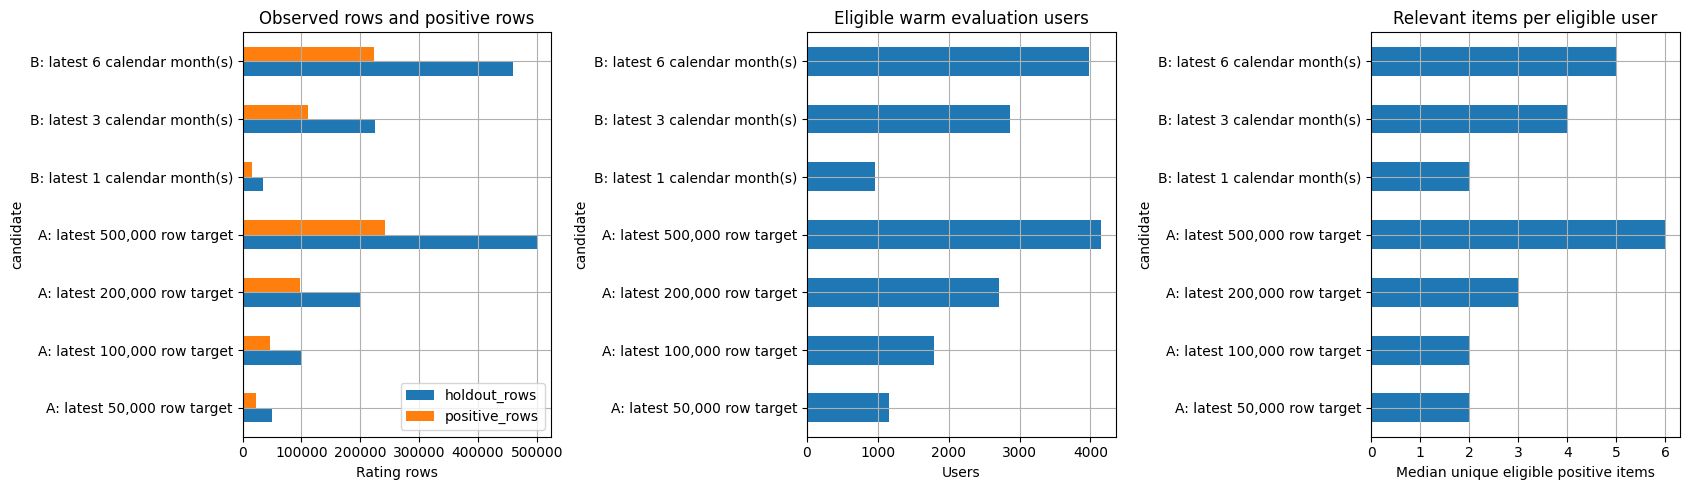

relevant_items_per_eligible_user,1,2,3–4,5–9,10+
candidate,,,,,
"A: latest 100,000 row target",587,324,315,303,258
"A: latest 200,000 row target",622,453,531,545,563
"A: latest 50,000 row target",457,219,217,149,122
"A: latest 500,000 row target",681,470,672,923,1403
B: latest 1 calendar month(s),408,197,166,110,83
B: latest 3 calendar month(s),628,454,577,587,614
B: latest 6 calendar month(s),675,461,665,859,1314


,history_rating_rows,history_positive_rows,holdout_rating_rows,holdout_positive_rows,raw_unique_positive_items,recommendable_unique_positive_items,eligible_warm_user
userId,,,,,,,
164366,3263,1321,79,11,11,9,True
146876,1652,163,108,10,10,10,True
76854,627,260,26,15,15,13,True
93575,3449,886,20,2,2,2,True
80552,583,387,20,10,10,10,True
98696,302,150,2,1,1,1,True
130583,3241,400,28,0,0,0,False
180322,1946,1117,15,11,11,11,True
102040,1558,556,2,1,1,0,False


In [15]:
def summarize_global(spec, return_user_details=False):
    left, right, cutoff = spec['start'], spec['end'], spec['cutoff']
    prior_rows, prior_pos, prior_item_rows, prior_seen_per_user = prefix_cache[left]
    hu, hi, hp = u[left:right], i[left:right], p[left:right]
    hold_user_rows = np.bincount(hu, minlength=U)
    hold_item_rows = np.bincount(hi, minlength=I)
    hold_positive_rows = np.bincount(hu[hp], minlength=U)
    test_users = hold_user_rows > 0
    positive_users = hold_positive_rows > 0
    warm = prior_rows > 0
    unseen_positive_rows = int((hp & (prior_item_rows[hi] == 0)).sum())
    sparse_item_positive_rows = int((hp & (prior_item_rows[hi] < MIN_ITEM_SUPPORT)).sum())
    raw_keys = hu[hp].astype('int64') * I + hi[hp]
    unique_keys = np.unique(raw_keys)
    label_users = unique_keys // I
    label_items = unique_keys % I
    label_counts = np.bincount(label_users, minlength=U)
    label_warm_items = prior_item_rows[label_items] > 0
    repeat_prior_pair = np.zeros(len(unique_keys), dtype=bool)
    if pair_first_times is not None and len(unique_keys):
        repeat_prior_pair = pair_first_times.reindex(unique_keys).to_numpy() < cutoff
    recommendable = label_warm_items & ~repeat_prior_pair
    relevant_counts = np.bincount(label_users[recommendable], minlength=U)
    eligible = (prior_pos >= MIN_HISTORY_POSITIVES) & (relevant_counts > 0)
    eligible_values = relevant_counts[eligible]
    base_catalog = int((prior_item_rows > 0).sum())
    # Unique prior seen-item counts are cached even when duplicate pairs exist.
    prior_seen_count = prior_seen_per_user[eligible]
    candidate_counts = base_catalog - prior_seen_count
    all_label_values = label_counts[positive_users]
    result = {key: value for key, value in spec.items() if key not in ('start', 'end', 'cutoff')}
    result.update({
        'start_index': left, 'end_index': right,
        'cutoff_utc': pd.to_datetime(cutoff, unit='s', utc=True),
        'last_holdout_utc': pd.to_datetime(int(t[right - 1]), unit='s', utc=True) if right > left else pd.NaT,
        'holdout_rows': right - left, 'positive_rows': int(hp.sum()),
        'distinct_holdout_users': int(test_users.sum()), 'distinct_holdout_movies': int((hold_item_rows > 0).sum()),
        'users_with_prior_ratings': int((test_users & warm).sum()),
        'new_user_proportion': float((test_users & ~warm).sum() / max(1, test_users.sum())),
        'sparse_user_proportion': float((test_users & (prior_pos < MIN_HISTORY_POSITIVES)).sum() / max(1, test_users.sum())),
        'sparse_warm_user_proportion': float((test_users & warm & (prior_pos < MIN_HISTORY_POSITIVES)).sum() / max(1, test_users.sum())),
        'positive_users': int(positive_users.sum()), 'unique_positive_labels': len(unique_keys),
        'raw_relevant_items_mean_per_positive_user': float(all_label_values.mean()) if len(all_label_values) else np.nan,
        'raw_relevant_items_median_per_positive_user': float(np.median(all_label_values)) if len(all_label_values) else np.nan,
        'unseen_item_positive_rows': unseen_positive_rows,
        'unseen_item_positive_share': unseen_positive_rows / max(1, int(hp.sum())),
        'new_item_count': int(((hold_item_rows > 0) & (prior_item_rows == 0)).sum()),
        'sparse_item_positive_rows': sparse_item_positive_rows,
        'sparse_item_positive_share': sparse_item_positive_rows / max(1, int(hp.sum())),
        'positive_labels_repeated_from_history': int(repeat_prior_pair.sum()),
        'eligible_warm_users': int(eligible.sum()),
        'eligible_user_coverage_of_positive_users': float(eligible.sum() / max(1, positive_users.sum())),
        'eligible_unique_relevant_labels': int(eligible_values.sum()),
        'eligible_relevant_items_mean': float(eligible_values.mean()) if len(eligible_values) else np.nan,
        'eligible_relevant_items_median': float(np.median(eligible_values)) if len(eligible_values) else np.nan,
        'eligible_relevant_items_p10': float(np.quantile(eligible_values, .1)) if len(eligible_values) else np.nan,
        'eligible_relevant_items_p90': float(np.quantile(eligible_values, .9)) if len(eligible_values) else np.nan,
        'eligible_users_with_one_relevant_item_share': float((eligible_values == 1).mean()) if len(eligible_values) else np.nan,
        'base_catalog_items': base_catalog,
        'mean_candidate_items_after_seen_filter': float(candidate_counts.mean()) if len(candidate_counts) else np.nan,
        'approx_user_item_scores': int(candidate_counts.sum()),
        'history_definition': 'strictly before global UTC cutoff',
    })
    for threshold in (1, 5, 10, 20):
        result[f'holdout_users_with_{threshold}_prior_positive_rows'] = int((test_users & (prior_pos >= threshold)).sum())
    if return_user_details:
        detail = pd.DataFrame({
            'history_rating_rows': prior_rows, 'history_positive_rows': prior_pos,
            'holdout_rating_rows': hold_user_rows, 'holdout_positive_rows': hold_positive_rows,
            'raw_unique_positive_items': label_counts,
            'recommendable_unique_positive_items': relevant_counts,
            'eligible_warm_user': eligible,
        }, index=user_index)
        detail.index.name = 'userId'
        return result, detail.loc[test_users]
    return result

global_comparison = pd.DataFrame([summarize_global(s) for s in specs])
display(global_comparison)
# Retain label multiplicity, not just total held-out rows, in the primary inspection view.
label_columns = ['candidate', 'holdout_rows', 'positive_rows', 'unique_positive_labels', 'positive_users',
    'eligible_warm_users', 'eligible_unique_relevant_labels', 'eligible_relevant_items_median',
    'eligible_users_with_one_relevant_item_share', 'new_user_proportion', 'unseen_item_positive_share',
    'sparse_item_positive_share', 'approx_user_item_scores']
display(global_comparison[label_columns])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
global_comparison.set_index('candidate')[['holdout_rows', 'positive_rows']].plot.barh(ax=axes[0])
global_comparison.set_index('candidate')['eligible_warm_users'].plot.barh(ax=axes[1])
global_comparison.set_index('candidate')['eligible_relevant_items_median'].plot.barh(ax=axes[2])
axes[0].set(title='Observed rows and positive rows', xlabel='Rating rows')
axes[1].set(title='Eligible warm evaluation users', xlabel='Users')
axes[2].set(title='Relevant items per eligible user', xlabel='Median unique eligible positive items')
fig.tight_layout()
plt.show()

# Inspect per-user evidence for each candidate without retaining seven extra copies of user tables.
label_multiplicity_tables = []
for study_spec in specs:
    _, user_detail = summarize_global(study_spec, return_user_details=True)
    counts = user_detail.loc[user_detail['eligible_warm_user'], 'recommendable_unique_positive_items']
    buckets = pd.cut(counts, bins=[0, 1, 2, 4, 9, np.inf], labels=['1', '2', '3–4', '5–9', '10+'])
    histogram = buckets.value_counts(sort=False).rename_axis('relevant_items_per_eligible_user').to_frame('users')
    histogram['candidate'] = study_spec['candidate']
    label_multiplicity_tables.append(histogram.reset_index())
label_multiplicity = pd.concat(label_multiplicity_tables, ignore_index=True)
display(label_multiplicity.pivot(index='candidate', columns='relevant_items_per_eligible_user', values='users'))
# user_detail is the final calendar candidate's compact per-user evidence, available for inspection.
display(user_detail.head(20))


**Interpretation:** a larger holdout can add labels while changing the eligible population, item exposure, and temporal distance.
Compare new-user shares with low-positive-history shares (the latter includes new users), and inspect sparse warm users separately.
`raw_relevant_items_*` counts unique positive items per positive holdout user before catalog/seen filtering;
`eligible_relevant_items_*` describes the actual warm-user benchmark after filtering.
A large one-label share can make per-user ranking metrics variable and heavily discrete. Later uncertainty analysis should use
user-level resampling or repeated time windows, without using test outcomes to tune models. Score counts are workload estimates,
not measured wall time or confidence intervals. Inspect chronological cohorts before choosing a window.

## 13. Supplementary per-user temporal protocols
**Objective:** compare leave-last-1 and leave-last-5 positive rows while requiring at least five earlier positive rows by default.
This is a separate exploratory protocol, not automatically the primary benchmark.
The kth-last-positive timestamp defines each user's cutoff; **all that user's ratings at or after it are held out**,
including lower ratings and timestamp ties. The number of positive rows may exceed k.
Users whose strictly earlier positives are insufficient after expanding ties are reported as tie-related exclusions.
Candidate items must have a rating by *some user* strictly before that user's cutoff; all of that user's prior rated items are excluded.
The same relevant-item and warm-label definitions as global windows apply.
This proxy catalog test uses first-seen observations, not future popularity counts.
Because users have different cutoffs, globally shared training on all other histories can leak future information.
A valid implementation would require cutoff-specific features/models or an explicitly less time-realistic benchmark.


In [16]:
def summarize_per_user(k):
    positive_user_codes = pd.Series(u[p], copy=False)
    positive_times = pd.Series(t[p], copy=False)
    # Rows are already globally chronological, so within-user cumcount requires no second full sort.
    rank_from_end = positive_user_codes.groupby(positive_user_codes, sort=False).cumcount(ascending=False)
    kth = rank_from_end.eq(k - 1).to_numpy()
    cutoff_by_user = np.full(U, np.iinfo(np.int64).max, dtype=np.int64)
    cutoff_by_user[positive_user_codes.to_numpy()[kth]] = positive_times.to_numpy()[kth]
    total_positive = np.bincount(u[p], minlength=U)
    nominal_users = total_positive >= k + PER_USER_MIN_RETAINED_POSITIVES
    cutoff_by_user[~nominal_users] = np.iinfo(np.int64).max
    prior_positive = np.zeros(U, dtype=np.int64)
    prior_rows = np.zeros(U, dtype=np.int64)
    prior_seen_per_user = np.zeros(U, dtype=np.int64)
    # Accumulate bounded chunks to avoid holding another full 32M-row mask.
    for left in range(0, N, CHUNK_ROWS):
        right = min(N, left + CHUNK_ROWS)
        history = t[left:right] < cutoff_by_user[u[left:right]]
        prior_rows += np.bincount(u[left:right][history], minlength=U)
        first_seen = history if first_pair_row is None else history & first_pair_row[left:right]
        prior_seen_per_user += np.bincount(u[left:right][first_seen], minlength=U)
        prior_positive += np.bincount(u[left:right][history & p[left:right]], minlength=U)
    protocol_users = nominal_users & (prior_positive >= PER_USER_MIN_RETAINED_POSITIVES)
    held_counts = np.zeros(U, dtype=np.int64)
    held_item_counts = np.zeros(I, dtype=np.int64)
    positive_row_counts = np.zeros(U, dtype=np.int64)
    unique_positive_counts = np.zeros(U, dtype=np.int64)
    relevant_counts = np.zeros(U, dtype=np.int64)
    prior_seen_counts = np.zeros(U, dtype=np.int64)
    unseen_item_positive_rows = 0
    prior_repeat_labels = 0
    all_relevant_keys = []
    # Histories are disjoint in time per user; pair deduplication happens after collecting only holdout positives.
    for left in range(0, N, CHUNK_ROWS):
        right = min(N, left + CHUNK_ROWS)
        cu, ci, ct, cp = u[left:right], i[left:right], t[left:right], p[left:right]
        held = protocol_users[cu] & (ct >= cutoff_by_user[cu])
        held_counts += np.bincount(cu[held], minlength=U)
        held_item_counts += np.bincount(ci[held], minlength=I)
        positive = held & cp
        positive_row_counts += np.bincount(cu[positive], minlength=U)
        unseen_item_positive_rows += int((positive & (item_first_t[ci] >= cutoff_by_user[cu])).sum())
        all_relevant_keys.append(cu[positive].astype('int64') * I + ci[positive])
    keys = np.unique(np.concatenate(all_relevant_keys)) if all_relevant_keys else np.array([], dtype='int64')
    lu, li = keys // I, keys % I
    unique_positive_counts += np.bincount(lu, minlength=U)
    known = item_first_t[li] < cutoff_by_user[lu]
    repeats = np.zeros(len(keys), dtype=bool)
    if pair_first_times is not None and len(keys):
        repeats = pair_first_times.reindex(keys).to_numpy() < cutoff_by_user[lu]
    prior_repeat_labels = int(repeats.sum())
    relevant_counts += np.bincount(lu[known & ~repeats], minlength=U)
    eligible = protocol_users & (prior_positive >= MIN_HISTORY_POSITIVES) & (relevant_counts > 0)
    label_values = relevant_counts[eligible]
    # First-seen timestamps for catalog-size estimates vary by user's cutoff, never global future popularity.
    sorted_item_first = np.sort(item_first_t)
    base_catalog_sizes = np.searchsorted(sorted_item_first, cutoff_by_user[eligible], side='left')
    prior_seen_counts = prior_seen_per_user[eligible]
    candidate_counts = base_catalog_sizes - prior_seen_counts
    return {
        'candidate': f'C: leave-last-{k}-positive (tie-expanded)', 'family': 'C: per-user supplementary',
        'target_positive_rows_per_user': k, 'nominal_protocol_users': int(nominal_users.sum()),
        'tie_history_excluded_users': int((nominal_users & ~protocol_users).sum()),
        'distinct_holdout_users': int(protocol_users.sum()), 'distinct_holdout_movies': int((held_item_counts > 0).sum()),
        'holdout_rows': int(held_counts.sum()), 'positive_rows': int(positive_row_counts.sum()),
        'unique_positive_labels': len(keys), 'positive_users': int((positive_row_counts > 0).sum()),
        'raw_relevant_items_mean_per_positive_user': float(unique_positive_counts[protocol_users].mean()) if protocol_users.any() else np.nan,
        'raw_relevant_items_median_per_positive_user': float(np.median(unique_positive_counts[protocol_users])) if protocol_users.any() else np.nan,
        'users_with_prior_ratings': int((protocol_users & (prior_rows > 0)).sum()),
        'new_user_proportion': 0.0 if protocol_users.any() else np.nan,
        'sparse_user_proportion': float((protocol_users & (prior_positive < MIN_HISTORY_POSITIVES)).sum() / max(1, protocol_users.sum())),
        'unseen_item_positive_rows': unseen_item_positive_rows,
        'unseen_item_positive_share': unseen_item_positive_rows / max(1, int(positive_row_counts.sum())),
        'positive_labels_repeated_from_history': prior_repeat_labels,
        'eligible_warm_users': int(eligible.sum()),
        'eligible_user_coverage_of_positive_users': eligible.sum() / max(1, int((positive_row_counts > 0).sum())),
        'eligible_unique_relevant_labels': int(label_values.sum()),
        'eligible_relevant_items_mean': float(label_values.mean()) if len(label_values) else np.nan,
        'eligible_relevant_items_median': float(np.median(label_values)) if len(label_values) else np.nan,
        'eligible_relevant_items_p10': float(np.quantile(label_values, .1)) if len(label_values) else np.nan,
        'eligible_relevant_items_p90': float(np.quantile(label_values, .9)) if len(label_values) else np.nan,
        'eligible_users_with_one_relevant_item_share': float((label_values == 1).mean()) if len(label_values) else np.nan,
        'mean_candidate_items_after_seen_filter': float(candidate_counts.mean()) if len(candidate_counts) else np.nan,
        'approx_user_item_scores': int(candidate_counts.sum()),
        'cutoff_utc': 'varies by user', 'boundary_ties': 'all equal-time rows held out per user',
        'history_definition': 'strictly before each user cutoff; not globally consistent',
        **{f'holdout_users_with_{h}_prior_positive_rows': int((protocol_users & (prior_positive >= h)).sum())
           for h in (1, 5, 10, 20)},
    }

per_user_comparison = pd.DataFrame([summarize_per_user(k) for k in (1, 5)])
split_comparison = pd.concat([global_comparison, per_user_comparison], ignore_index=True)
display(per_user_comparison)
print('Interpretation: per-user eligibility conditions preferentially select active users. Label and coverage '
      'gains do not remove global time leakage or make this population comparable to the global holdout population.')


,candidate,family,target_positive_rows_per_user,nominal_protocol_users,tie_history_excluded_users,distinct_holdout_users,distinct_holdout_movies,holdout_rows,positive_rows,unique_positive_labels,positive_users,raw_relevant_items_mean_per_positive_user,raw_relevant_items_median_per_positive_user,users_with_prior_ratings,new_user_proportion,sparse_user_proportion,unseen_item_positive_rows,unseen_item_positive_share,positive_labels_repeated_from_history,eligible_warm_users,eligible_user_coverage_of_positive_users,eligible_unique_relevant_labels,eligible_relevant_items_mean,eligible_relevant_items_median,eligible_relevant_items_p10,eligible_relevant_items_p90,eligible_users_with_one_relevant_item_share,mean_candidate_items_after_seen_filter,approx_user_item_scores,cutoff_utc,boundary_ties,history_definition,holdout_users_with_1_prior_positive_rows,holdout_users_with_5_prior_positive_rows,holdout_users_with_10_prior_positive_rows,holdout_users_with_20_prior_positive_rows
0,C: leave-last-1-positive (tie-expanded),C: per-user supplementary,1,198050,276,197774,23610,598791,245143,245143,197774,1.239511,1.0,197774,0.0,0.0,475,0.001938,0,197386,0.998038,244668,1.239541,1.0,1.0,2.0,0.895980,23758.157438,4689527664,varies by user,all equal-time rows held out per user,strictly before each user cutoff; not globally...,197774,197774,188081,152290
1,C: leave-last-5-positive (tie-expanded),C: per-user supplementary,5,191556,846,190710,37774,2288397,1004580,1004580,190710,5.267579,5.0,190710,0.0,0.0,17071,0.016993,0,190700,0.999948,987509,5.178338,5.0,5.0,6.0,0.001521,23774.248060,4533749105,varies by user,all equal-time rows held out per user,strictly before each user cutoff; not globally...,190710,190710,174700,139036


Interpretation: per-user eligibility conditions preferentially select active users. Label and coverage gains do not remove global time leakage or make this population comparable to the global holdout population.


## 14. Pre-test validation and ranker-training feasibility
**Objective:** inspect validation targets of 100K and 200K immediately before **each** global test candidate,
and distinct earlier ranker-training targets of 200K and 500K before each validation option.
All windows use the same whole-timestamp boundary policy; ranker, validation, and test intervals do not overlap.
History for each reported window ends at that window's start.
Counts of eligible positive users and raw labels estimate supervision only: no retrieval candidates,
negative examples, ranking features, or trained rankers are produced.
LightGBM/DeepFM require timestamp-safe candidate generation and labels; actual usable training groups can be much smaller.
No default equal allocation is made, and no protocol is approved by this study.


In [17]:
validation_comparison = pd.DataFrame([summarize_global(s) for s in validation_specs])
ranker_comparison = pd.DataFrame([summarize_global(s) for s in ranker_specs])
for table in (validation_comparison, ranker_comparison):
    table['meets_exploratory_volume_screen'] = (
        table['eligible_warm_users'].ge(MIN_EVAL_USERS) &
        table['eligible_unique_relevant_labels'].ge(MIN_ELIGIBLE_LABELS) &
        table['holdout_rows'].gt(0))
validation_view = ['test_candidate', 'target_rows', 'holdout_rows', 'cutoff_utc', 'last_holdout_utc',
    'positive_rows', 'eligible_warm_users', 'eligible_unique_relevant_labels',
    'eligible_relevant_items_median', 'unseen_item_positive_share', 'meets_exploratory_volume_screen']
display(validation_comparison[validation_view])
display(ranker_comparison[['test_candidate', 'validation_target', 'target_rows', 'holdout_rows',
    'cutoff_utc', 'last_holdout_utc', 'positive_rows', 'eligible_warm_users',
    'eligible_unique_relevant_labels', 'meets_exploratory_volume_screen']])
# Compare lifetime activity with history that is actually visible at the 100K test study cutoff.
reference_spec = next(s for s in specs if s.get('target_rows') == 100_000)
reference_prior_rows, reference_prior_pos, _, _ = prefix_cache[reference_spec['start']]
cutoff_history_comparison = pd.DataFrame({
    'lifetime_rating_rows': user_stats['rating_rows'].reindex(user_index).to_numpy(),
    'pre_reference_cutoff_rating_rows': reference_prior_rows,
    'lifetime_positive_rows': user_stats['positive_rows'].reindex(user_index).to_numpy(),
    'pre_reference_cutoff_positive_rows': reference_prior_pos,
}, index=user_index)
display(cutoff_history_comparison.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]))
print('100K is used only as an explicitly named reference for this history comparison, not selected as the test protocol.')
print('Validation windows meeting the exploratory volume screen:',
      int(validation_comparison['meets_exploratory_volume_screen'].sum()), '/', len(validation_comparison))
print('Ranker windows meeting the same supervision-volume screen:',
      int(ranker_comparison['meets_exploratory_volume_screen'].sum()), '/', len(ranker_comparison))


,test_candidate,target_rows,holdout_rows,cutoff_utc,last_holdout_utc,positive_rows,eligible_warm_users,eligible_unique_relevant_labels,eligible_relevant_items_median,unseen_item_positive_share,meets_exploratory_volume_screen
0,"A: latest 50,000 row target",100000,100000,2023-08-24 16:56:44+00:00,2023-09-25 20:11:23+00:00,50157,1855,11843,3.0,0.009211,True
1,"A: latest 50,000 row target",200000,200000,2023-07-24 07:35:21+00:00,2023-09-25 20:11:23+00:00,99179,2752,23123,4.0,0.007270,True
2,"A: latest 100,000 row target",100000,100000,2023-08-07 00:06:31+00:00,2023-09-10 10:59:41+00:00,51454,1962,12843,3.0,0.003848,True
3,"A: latest 100,000 row target",200000,200000,2023-07-08 16:23:14+00:00,2023-09-10 10:59:41+00:00,100209,2692,22583,4.0,0.014510,True
4,"A: latest 200,000 row target",100000,100000,2023-07-08 16:51:30+00:00,2023-08-07 00:09:09+00:00,48757,1822,12270,3.0,0.013147,True
5,"A: latest 200,000 row target",200000,200000,2023-05-23 19:22:46+00:00,2023-08-07 00:09:09+00:00,96243,2842,25813,4.0,0.013539,True
6,"A: latest 500,000 row target",100000,100000,2023-03-05 22:39:55+00:00,2023-04-15 15:44:22+00:00,47720,2105,16709,3.0,0.007020,True
7,"A: latest 500,000 row target",200000,200000,2023-01-29 14:50:43+00:00,2023-04-15 15:44:22+00:00,98705,3004,27972,4.0,0.008551,True
8,B: latest 1 calendar month(s),100000,100000,2023-08-29 22:59:50+00:00,2023-09-30 23:59:53+00:00,49134,1816,11233,2.5,0.009545,True
9,B: latest 1 calendar month(s),200000,200020,2023-07-29 13:50:56+00:00,2023-09-30 23:59:53+00:00,99420,2748,22920,4.0,0.007413,True


,test_candidate,validation_target,target_rows,holdout_rows,cutoff_utc,last_holdout_utc,positive_rows,eligible_warm_users,eligible_unique_relevant_labels,meets_exploratory_volume_screen
0,"A: latest 50,000 row target",100000,200000,200000,2023-06-17 03:15:21+00:00,2023-08-24 16:56:36+00:00,98144,2725,23583,True
1,"A: latest 50,000 row target",100000,500000,500000,2023-02-16 16:06:16+00:00,2023-08-24 16:56:36+00:00,241242,4309,58720,True
2,"A: latest 50,000 row target",200000,200000,200000,2023-05-04 13:32:30+00:00,2023-07-24 07:34:24+00:00,96308,2851,25520,True
3,"A: latest 50,000 row target",200000,500000,500000,2023-01-13 22:43:38+00:00,2023-07-24 07:34:24+00:00,243279,4390,60779,True
4,"A: latest 100,000 row target",100000,200000,200000,2023-05-23 19:19:27+00:00,2023-08-07 00:06:29+00:00,96242,2842,25818,True
5,"A: latest 100,000 row target",100000,500000,500000,2023-01-29 14:48:05+00:00,2023-08-07 00:06:29+00:00,242204,4349,59416,True
6,"A: latest 100,000 row target",200000,200000,200000,2023-04-15 15:28:32+00:00,2023-07-08 16:23:05+00:00,94743,2934,25803,True
7,"A: latest 100,000 row target",200000,500000,500000,2022-12-29 12:28:21+00:00,2023-07-08 16:23:05+00:00,242935,4421,60993,True
8,"A: latest 200,000 row target",100000,200000,200000,2023-04-15 15:44:47+00:00,2023-07-08 16:49:16+00:00,94743,2934,25801,True
9,"A: latest 200,000 row target",100000,500000,500000,2022-12-29 12:30:19+00:00,2023-07-08 16:49:16+00:00,242927,4421,60983,True


,lifetime_rating_rows,pre_reference_cutoff_rating_rows,lifetime_positive_rows,pre_reference_cutoff_positive_rows
count,200948.000000,200948.000000,200948.000000,200948.000000
mean,159.246193,158.748492,79.315201,79.082001
std,282.025462,281.357045,113.054736,112.863472
min,20.000000,0.000000,0.000000,0.000000
10%,25.000000,24.000000,13.000000,13.000000
25%,36.000000,36.000000,21.000000,21.000000
50%,73.000000,72.000000,42.000000,42.000000
75%,167.000000,166.000000,92.000000,92.000000
90%,364.000000,363.000000,183.000000,182.000000
95%,571.000000,570.000000,268.000000,268.000000


100K is used only as an explicitly named reference for this history comparison, not selected as the test protocol.
Validation windows meeting the exploratory volume screen: 14 / 14
Ranker windows meeting the same supervision-volume screen: 28 / 28


**Interpretation and tradeoffs:** review eligible users, unique relevant labels, label multiplicity, and compute together.
A short recent window offers temporal recency but may have mostly single-label users and limited movie exposure.
A longer window adds supervision and users but changes the task horizon and population. Warm-user filtering and a positive
threshold produce selection bias; a warm-only benchmark cannot establish performance for cold-start entities.
More held-out rows do not guarantee lower metric variance; per-user label counts and cohort heterogeneity matter.
A separate ranker window needs enough candidate groups **after** retrieval, seen-item filtering, and timestamp-safe feature generation.
Validation must support model comparison without consuming or tuning on test labels. Review these tables before approving allocation.

## 15. EDA Summary and Split Feasibility Comparison
**Objective:** generate an evidence-based handoff from actual computed statistics. No expected results are hardcoded.
The screening rule below provisionally favors the lowest estimated full-catalog scoring cost among globally consistent
candidates meeting the configured user, label, and coverage floors and having at least one viable validation/ranker allocation.
It requires clean duplicate-pair semantics. These floors are engineering review criteria, not a power analysis.
If none qualifies, the notebook recommends further protocol review rather than declaring a 100K holdout optimal.


In [18]:
summary_rows = {
    'observed_rating_rows': len(ratings), 'observed_positive_rows': int(p.sum()),
    'positive_rating_ratio': float(p.mean()), 'unique_rating_users': U, 'catalog_movies': I,
    'rated_movies': n_rated_items, 'zero_rating_catalog_movies': len(zero_rating_movies),
    'unique_user_movie_pairs': n_unique_pairs, 'pair_catalog_sparsity': 1 - n_unique_pairs / (U * I),
    'median_lifetime_user_rating_rows': float(user_stats['rating_rows'].median()),
    'P99_lifetime_user_rating_rows': float(user_stats['rating_rows'].quantile(.99)),
    'top_1pct_user_rating_share': float(concentration(user_stats['rating_rows']).iloc[0]['interaction_share']),
    'top_1pct_movie_rating_share': float(concentration(item_stats['rating_rows']).iloc[0]['interaction_share']),
    'catalog_tag_application_coverage': float(tag_apps_per_movie.gt(0).mean()),
    'duplicate_rating_pair_extra_rows': duplicate_pairs,
    'quality_checks_with_nonzero_counts': int(quality_summary['count'].gt(0).sum()),
    'first_observed_rating_utc': str(pd.to_datetime(int(t[0]), unit='s', utc=True)),
    'last_observed_rating_utc': str(last_time_utc),
}
display(Markdown('### EDA Summary'))
display(pd.Series(summary_rows, name='computed value').to_frame())
display(recent_volume)

display(Markdown('### Split Feasibility Comparison'))
comparison_columns = ['candidate', 'family', 'holdout_rows', 'positive_rows', 'unique_positive_labels',
    'distinct_holdout_users', 'eligible_warm_users', 'eligible_unique_relevant_labels',
    'eligible_relevant_items_median', 'eligible_users_with_one_relevant_item_share',
    'new_user_proportion', 'unseen_item_positive_share', 'approx_user_item_scores']
display(split_comparison[comparison_columns])

viable_ranker_parents = set(ranker_comparison.loc[
    ranker_comparison['meets_exploratory_volume_screen'], 'candidate'].str.rsplit(' | ranker target', n=1).str[0])
valid_validation = validation_comparison['meets_exploratory_volume_screen'] & validation_comparison['candidate'].isin(viable_ranker_parents)
viable_tests = set(validation_comparison.loc[valid_validation, 'test_candidate'])
review = global_comparison.copy()
review['has_viable_pretest_allocation'] = review['candidate'].isin(viable_tests)
review['passes_exploratory_screen'] = (
    review['eligible_warm_users'].ge(MIN_EVAL_USERS) &
    review['eligible_unique_relevant_labels'].ge(MIN_ELIGIBLE_LABELS) &
    review['eligible_user_coverage_of_positive_users'].ge(MIN_WARM_POSITIVE_USER_COVERAGE) &
    review['mean_candidate_items_after_seen_filter'].le(MAX_MEAN_CANDIDATES) &
    review['has_viable_pretest_allocation'] & (duplicate_pairs == 0))
display(review[['candidate', 'passes_exploratory_screen', 'has_viable_pretest_allocation',
    'eligible_user_coverage_of_positive_users', 'eligible_relevant_items_p10', 'eligible_relevant_items_p90']])
qualified = review.loc[review['passes_exploratory_screen']].sort_values(
    ['approx_user_item_scores', 'holdout_rows', 'candidate'])
if qualified.empty:
    recommendation = (
        'No global candidate satisfies the current exploratory user/label/coverage and pre-test allocation screens '
        'with clean pair semantics. Review the measured constraints, investigate data quality if needed, '
        'and consider additional calendar windows before proposing a protocol. No final allocation is selected.')
else:
    chosen = qualified.iloc[0]
    recommendation = (
        f'Provisional candidate for human review: **{chosen["candidate"]}**, beginning {chosen["cutoff_utc"]}. '
        f'It contains {int(chosen["holdout_rows"]):,} rating rows, {int(chosen["positive_rows"]):,} positive rows, '
        f'and {int(chosen["unique_positive_labels"]):,} unique positive labels before eligibility filtering. '
        f'The warm benchmark has {int(chosen["eligible_warm_users"]):,} eligible users and '
        f'{int(chosen["eligible_unique_relevant_labels"]):,} eligible relevant items across users; '
        f'median relevant items/user = {chosen["eligible_relevant_items_median"]:.1f}, '
        f'one-label user share = {chosen["eligible_users_with_one_relevant_item_share"]:.1%}. '
        f'It retains {chosen["eligible_user_coverage_of_positive_users"]:.1%} of positive-label users, '
        f'has {chosen["unseen_item_positive_share"]:.1%} positive rows involving unseen items, '
        f'and needs about {int(chosen["approx_user_item_scores"]):,} full-catalog user–item scores. '
        'It is the lowest estimated scoring workload among candidates meeting the configured screens, '
        'and at least one separate preceding validation/ranker allocation clears the volume screens. '
        'This is an engineering shortlist, not proof of statistical optimality. '
        'Review label sparsity, cohort bias, metadata availability, and uncertainty before approving any split.')
display(Markdown('### Provisional recommendation\n\n' + recommendation))
print('No models trained. No final split created or saved. Approval is still required for an evaluation protocol.')


### EDA Summary

,computed value
observed_rating_rows,32000204
observed_positive_rows,15938231
positive_rating_ratio,0.498067
unique_rating_users,200948
catalog_movies,87585
rated_movies,84432
zero_rating_catalog_movies,3153
unique_user_movie_pairs,32000204
pair_catalog_sparsity,0.998182
median_lifetime_user_rating_rows,73.0


,lookback_years,start_utc,rating_rows,share_of_all_rows
0,1,2022-10-13 02:29:07+00:00,988745,0.030898
1,3,2020-10-13 02:29:07+00:00,3302471,0.103202
2,5,2018-10-13 02:29:07+00:00,6362637,0.198831


### Split Feasibility Comparison

,candidate,family,holdout_rows,positive_rows,unique_positive_labels,distinct_holdout_users,eligible_warm_users,eligible_unique_relevant_labels,eligible_relevant_items_median,eligible_users_with_one_relevant_item_share,new_user_proportion,unseen_item_positive_share,approx_user_item_scores
0,"A: latest 50,000 row target",A: global row target,50000,23071,23071,1813,1164,7001,2.0,0.392612,0.098731,0.008669,96949356
1,"A: latest 100,000 row target",A: global row target,100012,46861,46861,2680,1787,12261,2.0,0.328483,0.144776,0.012420,147753922
2,"A: latest 200,000 row target",A: global row target,200000,98309,98309,4006,2714,22960,3.0,0.229182,0.211932,0.008890,223313708
3,"A: latest 500,000 row target",A: global row target,500000,241809,241809,6694,4149,52935,6.0,0.164136,0.317150,0.022154,335681434
4,B: latest 1 calendar month(s),B: calendar window,33804,15559,15559,1481,964,5659,2.0,0.423237,0.079676,0.006813,80332993
5,B: latest 3 calendar month(s),B: calendar window,224702,110853,110853,4243,2860,24504,4.0,0.219580,0.224370,0.008579,235073921
6,B: latest 6 calendar month(s),B: calendar window,459833,222919,222919,6366,3974,49677,5.0,0.169854,0.308514,0.021968,322425383
7,C: leave-last-1-positive (tie-expanded),C: per-user supplementary,598791,245143,245143,197774,197386,244668,1.0,0.895980,0.000000,0.001938,4689527664
8,C: leave-last-5-positive (tie-expanded),C: per-user supplementary,2288397,1004580,1004580,190710,190700,987509,5.0,0.001521,0.000000,0.016993,4533749105


,candidate,passes_exploratory_screen,has_viable_pretest_allocation,eligible_user_coverage_of_positive_users,eligible_relevant_items_p10,eligible_relevant_items_p90
0,"A: latest 50,000 row target",True,True,0.838617,1.0,10.0
1,"A: latest 100,000 row target",True,True,0.803146,1.0,13.4
2,"A: latest 200,000 row target",True,True,0.753052,1.0,18.0
3,"A: latest 500,000 row target",True,True,0.649804,1.0,29.0
4,B: latest 1 calendar month(s),False,True,0.871609,1.0,8.0
5,B: latest 3 calendar month(s),True,True,0.742086,1.0,19.0
6,B: latest 6 calendar month(s),True,True,0.655992,1.0,28.0


### Provisional recommendation

Provisional candidate for human review: **A: latest 50,000 row target**, beginning 2023-09-25 20:11:40+00:00. It contains 50,000 rating rows, 23,071 positive rows, and 23,071 unique positive labels before eligibility filtering. The warm benchmark has 1,164 eligible users and 7,001 eligible relevant items across users; median relevant items/user = 2.0, one-label user share = 39.3%. It retains 83.9% of positive-label users, has 0.9% positive rows involving unseen items, and needs about 96,949,356 full-catalog user–item scores. It is the lowest estimated scoring workload among candidates meeting the configured screens, and at least one separate preceding validation/ranker allocation clears the volume screens. This is an engineering shortlist, not proof of statistical optimality. Review label sparsity, cohort bias, metadata availability, and uncertainty before approving any split.

No models trained. No final split created or saved. Approval is still required for an evaluation protocol.


## Rating Burst Analysis: Temporal Concentration and Retrospective Rating Behaviour

**Objective:** investigate how concentrated each user's rating submissions are in calendar periods and inactivity-defined
sessions. MovieLens records **rating-submission timestamps**, which need not be movie-viewing timestamps.
Concentrated submissions are compatible with batch or retrospective rating, but ratings alone cannot prove that explanation,
identify when a movie was watched, or establish the order of consumption. Interface design, onboarding, and other unobserved
processes could also affect submission patterns.

Run **only these appended cells** in the existing Colab runtime after the preceding EDA. They reuse the in-memory `ratings`,
NumPy, pandas, Matplotlib, and display utilities; `user_stats`, when available, is a read-only consistency check.
No CSV is reloaded, no dataset is downloaded, no existing DataFrame is mutated, and no evaluation allocation is changed.
All measures describe the **complete observed history**, not history available at a prospective training cutoff.

**Time definitions:** Unix seconds are interpreted in timezone-aware UTC. A calendar day is `[00:00, next 00:00)` UTC;
a calendar hour is `[HH:00, next HH:00)` on a particular UTC date. These are **not** rolling 24-hour or 60-minute windows.
Equal-second ties keep their original row-position order through one stable indirect user/time sort; their chronological
order within that second remains unidentifiable. Each user's first submission has no preceding gap.

**Resources:** the code sorts only user IDs/timestamps, never a copy of all rating columns. The sorted timestamps and gap
array retain about 16 bytes per rating plus small user tables. Sorting, exact quantiles, and run-length calculations need
additional temporary memory, potentially several GB at 32M rows; use a high-memory CPU Colab runtime.
Calendar comparisons use bounded chunks. All three session thresholds reuse the same ordering, and per-session arrays
are released inside each aggregation. Event arrays are released after the final discussion. New outputs are intentionally
empty until you execute the appended cells; no burst statistics are assumed here.


In [19]:
SESSION_GAP_MINUTES = 30
BURST_SENSITIVITY_MINUTES = (10, 60)
BURST_CHUNK_ROWS = 1_000_000
BURST_HISTOGRAM_BINS = 60

if 'ratings' not in globals():
    raise RuntimeError('The in-memory ratings DataFrame is required. Use the runtime containing the completed EDA.')
if not np.isfinite(SESSION_GAP_MINUTES) or SESSION_GAP_MINUTES <= 0:
    raise ValueError('SESSION_GAP_MINUTES must be a finite positive number.')
if not isinstance(BURST_CHUNK_ROWS, (int, np.integer)) or BURST_CHUNK_ROWS < 1:
    raise ValueError('BURST_CHUNK_ROWS must be a positive integer.')


def _burst_describe(values):
    """Exact, explicitly named summaries; P50 and median are intentionally both shown."""
    series = pd.Series(values, copy=False)
    quantiles = series.quantile([.10, .25, .50, .75, .90, .95, .99])
    return pd.Series({
        'count': len(series), 'minimum': series.min(), 'mean': series.mean(), 'median': series.median(),
        **{f'P{int(q * 100)}': value for q, value in quantiles.items()}, 'maximum': series.max(),
    })


def _burst_log_histogram(values, bins=60):
    """Aggregate positive integer values only; zero gaps are reported separately."""
    upper = max(2.0, float(np.max(values)) + 1) if len(values) else 2.0
    edges = np.geomspace(1, upper, bins + 1)
    counts, edges = np.histogram(values, bins=edges)
    return counts, edges


def _burst_prepare_events(frame):
    required = {'userId', 'timestamp'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Rating burst analysis requires columns {sorted(required)}.')
    if frame.empty:
        raise ValueError('Rating burst analysis requires at least one observed rating row.')
    for column in required:
        if not pd.api.types.is_integer_dtype(frame[column]) or frame[column].isna().any():
            raise ValueError(f'{column} must contain nonmissing integers; inspect the existing Data Quality audit.')
    if frame['userId'].min() <= 0:
        raise ValueError('userId must be positive; no observations were removed.')
    # This range also guarantees subtraction cannot overflow int64 and UTC display is representable.
    max_utc_second = pd.Timestamp.max.value // 1_000_000_000
    if frame['timestamp'].min() < 0 or frame['timestamp'].max() > max_utc_second:
        raise ValueError('Timestamps must be nonnegative UTC Unix seconds within pandas datetime range; no rows were removed.')
    timestamps = frame['timestamp'].to_numpy(dtype='int64', copy=False)
    user_ids = frame['userId'].to_numpy(copy=False)
    if user_ids.dtype.kind not in 'iu':
        user_ids = frame['userId'].to_numpy(dtype='int64', copy=False)
    # np.lexsort is stable: equal user/time keys retain their input positional order.
    order = np.lexsort((timestamps, user_ids))
    sorted_times = timestamps[order]
    sorted_users = user_ids[order]
    user_boundary = np.empty(len(frame), dtype=bool)
    user_boundary[0] = True
    user_boundary[1:] = sorted_users[1:] != sorted_users[:-1]
    user_starts = np.flatnonzero(user_boundary)
    user_ends = np.r_[user_starts[1:], len(frame)]
    user_table = pd.DataFrame({
        'total_ratings': user_ends - user_starts,
        'first_timestamp': sorted_times[user_starts],
        'last_timestamp': sorted_times[user_ends - 1],
    }, index=pd.Index(sorted_users[user_starts], name='userId'))
    user_table['activity_span_seconds'] = user_table['last_timestamp'] - user_table['first_timestamp']
    user_table['activity_span_days'] = user_table['activity_span_seconds'] / 86400
    user_table['first_rating_utc'] = pd.to_datetime(user_table['first_timestamp'], unit='s', utc=True)
    user_table['last_rating_utc'] = pd.to_datetime(user_table['last_timestamp'], unit='s', utc=True)
    gaps = np.empty(len(frame), dtype='int64')
    gaps[0] = -1
    np.subtract(sorted_times[1:], sorted_times[:-1], out=gaps[1:])
    gaps[user_starts] = -1  # Sentinel: no preceding event, excluded from every gap denominator.
    if np.any(gaps < -1):
        raise AssertionError('Unexpected negative within-user gap after chronological ordering.')
    return user_table, sorted_times, gaps, user_starts


def _burst_calendar_counts(sorted_times, user_starts, unit_seconds, chunk_rows):
    """Count contiguous UTC bucket runs without creating a 32M-row grouping DataFrame."""
    boundaries = np.empty(len(sorted_times), dtype=bool)
    boundaries[0] = True
    for left in range(1, len(sorted_times), chunk_rows):
        right = min(len(sorted_times), left + chunk_rows)
        boundaries[left:right] = (sorted_times[left:right] // unit_seconds !=
                                  sorted_times[left - 1:right - 1] // unit_seconds)
    boundaries[user_starts] = True
    starts = np.flatnonzero(boundaries)
    lengths = np.diff(np.r_[starts, len(sorted_times)])
    first_run_per_user = np.searchsorted(starts, user_starts)
    active_buckets = np.diff(np.r_[first_run_per_user, len(starts)])
    maximum_per_bucket = np.maximum.reduceat(lengths, first_run_per_user)
    return active_buckets, maximum_per_bucket


### User-level submission concentration
**Objective:** quantify first/last submission times, full observed activity spans, distinct dated UTC buckets, and peak
calendar counts. A user active at 23:59 and 00:01 occupies two UTC days even though the submissions are two minutes apart.
Percentages below use each user's own total rating rows, including tied submissions and any duplicates retained by the
existing audit. Spans measure elapsed first-to-last time, not continuous activity or membership duration.


In [20]:
burst_user_stats, burst_sorted_timestamps, burst_inter_rating_gaps, burst_user_starts = _burst_prepare_events(ratings)
for burst_unit_label, burst_unit_seconds in [('day', 86400), ('hour', 3600)]:
    burst_active_buckets, burst_maximum_bucket = _burst_calendar_counts(
        burst_sorted_timestamps, burst_user_starts, burst_unit_seconds, BURST_CHUNK_ROWS)
    burst_user_stats[f'distinct_active_utc_{burst_unit_label}s'] = burst_active_buckets
    burst_user_stats[f'max_ratings_in_utc_{burst_unit_label}'] = burst_maximum_bucket
    burst_user_stats[f'pct_on_most_active_{burst_unit_label}'] = (
        100 * burst_maximum_bucket / burst_user_stats['total_ratings'].to_numpy())
if 'user_stats' in globals() and {'rating_rows', 'first_timestamp', 'last_timestamp'}.issubset(user_stats.columns):
    burst_prior_user_check = user_stats.reindex(burst_user_stats.index)
    if (len(user_stats) != len(burst_user_stats) or
        not np.array_equal(burst_prior_user_check['rating_rows'].to_numpy(), burst_user_stats['total_ratings'].to_numpy()) or
        not np.array_equal(burst_prior_user_check['first_timestamp'].to_numpy(), burst_user_stats['first_timestamp'].to_numpy()) or
        not np.array_equal(burst_prior_user_check['last_timestamp'].to_numpy(), burst_user_stats['last_timestamp'].to_numpy())):
        raise ValueError('The existing user_stats and current ratings disagree; inspect runtime state before interpreting burst results.')
    print('Read-only consistency check against existing user_stats passed.')
print(f'Observed rating rows: {len(ratings):,}; users: {len(burst_user_stats):,}. UTC calendar periods are not rolling windows.')
print(f'Sorted timestamps plus gap-array storage: {(burst_sorted_timestamps.nbytes + burst_inter_rating_gaps.nbytes) / 2**20:.1f} MiB; '
      'sorting/run/quantile temporaries require additional RAM.')
display(burst_user_stats.head(10))
burst_user_summary_columns = [
    'total_ratings', 'first_timestamp', 'last_timestamp', 'activity_span_seconds', 'activity_span_days',
    'distinct_active_utc_days', 'distinct_active_utc_hours', 'max_ratings_in_utc_day',
    'max_ratings_in_utc_hour', 'pct_on_most_active_day', 'pct_on_most_active_hour',
]
burst_user_summary = pd.DataFrame({column: _burst_describe(burst_user_stats[column])
                                   for column in burst_user_summary_columns}).T
display(burst_user_summary)
print('Interpretation: compare calendar concentration with activity span and distinct active periods. '
      'Large counts describe submission density, not a count of movies consumed during those periods.')


Read-only consistency check against existing user_stats passed.
Observed rating rows: 32,000,204; users: 200,948. UTC calendar periods are not rolling windows.
Sorted timestamps plus gap-array storage: 488.3 MiB; sorting/run/quantile temporaries require additional RAM.


,total_ratings,first_timestamp,last_timestamp,activity_span_seconds,activity_span_days,first_rating_utc,last_rating_utc,distinct_active_utc_days,max_ratings_in_utc_day,pct_on_most_active_day,distinct_active_utc_hours,max_ratings_in_utc_hour,pct_on_most_active_hour
userId,,,,,,,,,,,,,
1,141,943226846,944256398,1029552,11.916111,1999-11-21 23:27:26+00:00,1999-12-03 21:26:38+00:00,4,51,36.170213,8,32,22.695035
2,52,836423201,836424241,1040,0.012037,1996-07-03 19:46:41+00:00,1996-07-03 20:04:01+00:00,1,52,100.000000,2,43,82.692308
3,147,1084484354,1084486164,1810,0.020949,2004-05-13 21:39:14+00:00,2004-05-13 22:09:24+00:00,1,147,100.000000,2,136,92.517007
4,27,960485234,960485723,489,0.005660,2000-06-08 17:27:14+00:00,2000-06-08 17:35:23+00:00,1,27,100.000000,1,27,100.000000
5,33,840763913,840768897,4984,0.057685,1996-08-23 01:31:53+00:00,1996-08-23 02:54:57+00:00,1,33,100.000000,2,20,60.606061
6,26,1100059902,1100062907,3005,0.034780,2004-11-10 04:11:42+00:00,2004-11-10 05:01:47+00:00,1,26,100.000000,2,16,61.538462
7,44,840385452,840386223,771,0.008924,1996-08-18 16:24:12+00:00,1996-08-18 16:37:03+00:00,1,44,100.000000,1,44,100.000000
8,31,1553765387,1553767405,2018,0.023356,2019-03-28 09:29:47+00:00,2019-03-28 10:03:25+00:00,1,31,100.000000,2,30,96.774194
9,58,1138474042,1142458727,3984685,46.119039,2006-01-28 18:47:22+00:00,2006-03-15 21:38:47+00:00,4,23,39.655172,4,23,39.655172


,count,minimum,mean,median,P10,P25,P50,P75,P90,P95,P99,maximum
total_ratings,200948.0,2.000000e+01,1.592462e+02,7.300000e+01,2.500000e+01,3.600000e+01,7.300000e+01,1.670000e+02,3.640000e+02,5.710000e+02,1.290000e+03,3.333200e+04
first_timestamp,200948.0,7.896520e+08,1.216057e+09,1.208339e+09,8.460736e+08,9.595454e+08,1.208339e+09,1.463840e+09,1.584688e+09,1.622659e+09,1.682443e+09,1.697159e+09
last_timestamp,200948.0,8.250802e+08,1.238445e+09,1.235181e+09,8.480666e+08,9.704599e+08,1.235181e+09,1.489693e+09,1.612211e+09,1.665888e+09,1.695482e+09,1.697164e+09
activity_span_seconds,200948.0,0.000000e+00,2.238778e+07,5.641000e+03,4.180000e+02,9.700000e+02,5.641000e+03,4.585718e+06,6.125602e+07,1.380535e+08,3.831599e+08,8.221081e+08
activity_span_days,200948.0,0.000000e+00,2.591179e+02,6.528935e-02,4.837963e-03,1.122685e-02,6.528935e-02,5.307545e+01,7.089817e+02,1.597842e+03,4.434721e+03,9.515140e+03
distinct_active_utc_days,200948.0,1.000000e+00,9.598956e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,1.100000e+01,3.000000e+01,1.720000e+02,3.704000e+03
distinct_active_utc_hours,200948.0,1.000000e+00,1.280796e+01,2.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00,1.700000e+01,4.100000e+01,2.150000e+02,5.472000e+03
max_ratings_in_utc_day,200948.0,2.000000e+00,1.019634e+02,5.900000e+01,2.300000e+01,3.200000e+01,5.900000e+01,1.180000e+02,2.190000e+02,3.140000e+02,6.260000e+02,6.456000e+03
max_ratings_in_utc_hour,200948.0,1.000000e+00,7.641860e+01,5.000000e+01,2.100000e+01,2.900000e+01,5.000000e+01,9.300000e+01,1.550000e+02,2.070000e+02,3.690000e+02,6.455000e+03
pct_on_most_active_day,200948.0,4.575496e-01,8.340193e+01,1.000000e+02,4.274809e+01,6.860747e+01,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02


Interpretation: compare calendar concentration with activity span and distinct active periods. Large counts describe submission density, not a count of movies consumed during those periods.


### Inter-rating time gaps
**Objective:** measure consecutive submission timing within each user. The denominator is `number of rating rows − number
of users`: first submissions have no preceding event and are excluded. Every remaining gap is nonnegative; tied timestamps
produce valid zero-second pairs. The “within” thresholds below are **inclusive and cumulative**, so they overlap and
must not be summed. “Longer than 24 hours” is strictly greater than 86,400 seconds.
Exact gap quantiles include zeros. The log histogram later shows positive gaps only and annotates the separate zero share.


In [21]:
def _burst_gap_report(gaps):
    valid = gaps[gaps >= 0]
    denominator = len(valid)
    # These loops cover a handful of thresholds, never individual ratings.
    rows = [{'threshold': 'Exactly 0 seconds', 'consecutive_pairs': int(np.count_nonzero(valid == 0))}]
    for label, seconds in [('Within 10 seconds', 10), ('Within 30 seconds', 30), ('Within 60 seconds', 60),
                           ('Within 5 minutes', 300), ('Within 30 minutes', 1800), ('Within 1 hour', 3600)]:
        rows.append({'threshold': label, 'consecutive_pairs': int(np.count_nonzero(valid <= seconds))})
    rows.append({'threshold': 'Longer than 24 hours', 'consecutive_pairs': int(np.count_nonzero(valid > 86400))})
    table = pd.DataFrame(rows)
    table['valid_within_user_pair_denominator'] = denominator
    table['pct_of_valid_pairs'] = 100 * table['consecutive_pairs'] / denominator if denominator else np.nan
    stats = _burst_describe(valid).to_frame('gap_seconds')
    histogram = _burst_log_histogram(valid, BURST_HISTOGRAM_BINS)
    return table, stats, histogram

burst_gap_thresholds, burst_gap_quantiles, burst_gap_histogram = _burst_gap_report(burst_inter_rating_gaps)
assert int(burst_gap_thresholds['valid_within_user_pair_denominator'].iloc[0]) == len(ratings) - len(burst_user_stats)
display(burst_gap_thresholds)
display(burst_gap_quantiles)
print('Interpretation: short and zero-second gaps can indicate closely grouped submissions. '
      'They cannot establish independent viewing events, the reason for the grouping, or the viewing order.')


,threshold,consecutive_pairs,valid_within_user_pair_denominator,pct_of_valid_pairs
0,Exactly 0 seconds,5262395,31799256,16.548799
1,Within 10 seconds,16139884,31799256,50.755540
2,Within 30 seconds,23282412,31799256,73.216845
3,Within 60 seconds,26408124,31799256,83.046358
4,Within 5 minutes,29147498,31799256,91.660943
5,Within 30 minutes,29683787,31799256,93.347426
6,Within 1 hour,29751634,31799256,93.560786
7,Longer than 24 hours,1439779,31799256,4.527713


,gap_seconds
count,3.179926e+07
minimum,0.000000e+00
mean,1.414744e+05
median,1.000000e+01
P10,0.000000e+00
P25,3.000000e+00
P50,1.000000e+01
P75,3.400000e+01
P90,1.690000e+02
P95,6.765300e+04


Interpretation: short and zero-second gaps can indicate closely grouped submissions. They cannot establish independent viewing events, the reason for the grouping, or the viewing order.


### Inactivity-defined rating sessions and threshold sensitivity
**Objective:** group consecutive same-user submissions when their gap is **no greater than** the inactivity threshold.
The default is `SESSION_GAP_MINUTES = 30`; 10- and 60-minute definitions are sensitivity checks.
User changes always start new sessions, including when two users share a timestamp.

An inactivity-defined session is a **chain** of nearby submissions, not a rolling window or a maximum-length session:
its total duration can exceed the inactivity threshold. Session duration is last minus first submission time, so a
single-rating or equal-second session can have zero duration. Here a “large” session is described at several explicit
support thresholds: 10, 20, and 50 rating rows. Session summaries and per-user maxima are retained; large per-event and
per-session tables are not. Sensitivity rows are separate descriptions, not pooled or independent samples.


In [22]:
def _burst_session_report(sorted_times, gaps, user_starts, gap_minutes):
    if not np.isfinite(gap_minutes) or gap_minutes <= 0:
        raise ValueError('The inactivity threshold must be finite and positive.')
    session_start = (gaps < 0) | (gaps > gap_minutes * 60)
    starts = np.flatnonzero(session_start)
    del session_start
    sizes = np.diff(np.r_[starts, len(sorted_times)])
    ends = starts + sizes - 1
    durations = sorted_times[ends] - sorted_times[starts]
    offsets = np.searchsorted(starts, user_starts)
    sessions_per_user = np.diff(np.r_[offsets, len(starts)])
    max_size_per_user = np.maximum.reduceat(sizes, offsets)
    if sizes.sum() != len(sorted_times) or np.any(durations < 0):
        raise AssertionError('Session aggregation failed to preserve all rating rows.')
    summary = {
        'inactivity_threshold_minutes': gap_minutes,
        'total_sessions': len(starts), 'rating_rows': len(sorted_times),
        'users': len(user_starts), 'mean_sessions_per_user': sessions_per_user.mean(),
        'mean_ratings_per_session': sizes.mean(), 'median_ratings_per_session': float(np.median(sizes)),
        'maximum_ratings_in_one_session': sizes.max(),
        'median_session_duration_seconds': float(np.median(durations)),
        'maximum_session_duration_seconds': durations.max(),
    }
    for minimum in (10, 20, 50):
        in_large_sessions = int(sizes[sizes >= minimum].sum())
        users_with_large = int(np.count_nonzero(max_size_per_user >= minimum))
        summary[f'rating_rows_in_sessions_ge_{minimum}'] = in_large_sessions
        summary[f'pct_ratings_in_sessions_ge_{minimum}'] = 100 * in_large_sessions / len(sorted_times)
        summary[f'users_with_session_ge_{minimum}'] = users_with_large
        summary[f'fraction_users_with_session_ge_{minimum}'] = users_with_large / len(user_starts)
    size_summary = _burst_describe(sizes)
    duration_summary = _burst_describe(durations)
    histogram = _burst_log_histogram(sizes, BURST_HISTOGRAM_BINS)
    return {'summary': summary, 'sessions_per_user': sessions_per_user,
            'max_ratings_per_user_session': max_size_per_user,
            'size_summary': size_summary, 'duration_summary': duration_summary, 'histogram': histogram}

burst_session_results = {}
for burst_threshold in dict.fromkeys((SESSION_GAP_MINUTES, *BURST_SENSITIVITY_MINUTES)):
    burst_session_results[burst_threshold] = _burst_session_report(
        burst_sorted_timestamps, burst_inter_rating_gaps, burst_user_starts, burst_threshold)
burst_session_sensitivity = pd.DataFrame([result['summary'] for result in burst_session_results.values()])
display(burst_session_sensitivity)
burst_default_sessions = burst_session_results[SESSION_GAP_MINUTES]
burst_user_stats['sessions_default_threshold'] = burst_default_sessions['sessions_per_user']
burst_user_stats['max_ratings_in_one_session'] = burst_default_sessions['max_ratings_per_user_session']
burst_user_stats['pct_in_largest_session'] = (
    100 * burst_user_stats['max_ratings_in_one_session'] / burst_user_stats['total_ratings'])
burst_session_summary = pd.DataFrame({
    'ratings_per_session': burst_default_sessions['size_summary'],
    'session_duration_seconds': burst_default_sessions['duration_summary'],
    'sessions_per_user': _burst_describe(burst_user_stats['sessions_default_threshold']),
    'largest_session_ratings_per_user': _burst_describe(burst_user_stats['max_ratings_in_one_session']),
})
display(burst_session_summary)
print('Interpretation: compare all three thresholds and duration quantiles. More connected sessions under a '
      'larger gap threshold are a definitional effect, not independent evidence for retrospective viewing.')


,inactivity_threshold_minutes,total_sessions,rating_rows,users,mean_sessions_per_user,mean_ratings_per_session,median_ratings_per_session,maximum_ratings_in_one_session,median_session_duration_seconds,maximum_session_duration_seconds,rating_rows_in_sessions_ge_10,pct_ratings_in_sessions_ge_10,users_with_session_ge_10,fraction_users_with_session_ge_10,rating_rows_in_sessions_ge_20,pct_ratings_in_sessions_ge_20,users_with_session_ge_20,fraction_users_with_session_ge_20,rating_rows_in_sessions_ge_50,pct_ratings_in_sessions_ge_50,users_with_session_ge_50,fraction_users_with_session_ge_50
0,30,2316417,32000204,200948,11.527445,13.814526,1.0,6456,0.0,39544,28475692,88.985970,200554,0.998039,26833066,83.852797,193483,0.962851,21347923,66.711834,112712,0.560901
1,10,2529124,32000204,200948,12.585963,12.652683,1.0,6454,0.0,31857,28096752,87.801790,200316,0.996855,26163386,81.760060,190141,0.946220,20358973,63.621385,108848,0.541672
2,60,2248570,32000204,200948,11.189810,14.231358,1.0,6456,0.0,46906,28576708,89.301643,200604,0.998288,27012987,84.415046,194202,0.966429,21668480,67.713568,113794,0.566286


,ratings_per_session,session_duration_seconds,sessions_per_user,largest_session_ratings_per_user
count,2.316417e+06,2.316417e+06,200948.000000,200948.000000
minimum,1.000000e+00,0.000000e+00,1.000000,1.000000
mean,1.381453e+01,4.309552e+02,11.527445,94.967559
median,1.000000e+00,0.000000e+00,2.000000,57.000000
P10,1.000000e+00,0.000000e+00,1.000000,22.000000
P25,1.000000e+00,0.000000e+00,1.000000,31.000000
P50,1.000000e+00,0.000000e+00,2.000000,57.000000
P75,5.000000e+00,3.380000e+02,4.000000,110.000000
P90,3.300000e+01,1.370000e+03,14.000000,202.000000
P95,6.900000e+01,2.299000e+03,36.000000,287.000000


Interpretation: compare all three thresholds and duration quantiles. More connected sessions under a larger gap threshold are a definitional effect, not independent evidence for retrospective viewing.


### Temporal concentration across users and activity cohorts
**Objective:** report both user counts and proportions for concentration thresholds, then compare like-sized histories.
Each user contributes equally to user percentages; rating-weighted session shares are shown separately above.
Cohorts use full-data rating-row counts. A `<20` cohort is reported separately if present in the mirror and should not
drive conclusions about broader users. Empty cohorts retain zero user counts and undefined percentages.
A high fraction for a user with few observations has different evidential weight from the same fraction for a very active user.


In [23]:
burst_concentration_flags = pd.DataFrame({
    'at_least_50pct_on_one_utc_day': burst_user_stats['pct_on_most_active_day'].ge(50),
    'at_least_80pct_on_one_utc_day': burst_user_stats['pct_on_most_active_day'].ge(80),
    'at_least_90pct_on_one_utc_day': burst_user_stats['pct_on_most_active_day'].ge(90),
    'at_least_50pct_in_one_session': burst_user_stats['pct_in_largest_session'].ge(50),
    'at_least_80pct_in_one_session': burst_user_stats['pct_in_largest_session'].ge(80),
}, index=burst_user_stats.index)
burst_concentration_summary = pd.DataFrame({
    'users': burst_concentration_flags.sum(),
    'user_denominator': len(burst_user_stats),
    'fraction_of_users': burst_concentration_flags.mean(),
    'pct_of_users': 100 * burst_concentration_flags.mean(),
})
display(burst_concentration_summary)
burst_activity_cohort = pd.cut(burst_user_stats['total_ratings'], bins=[0, 19, 49, 99, 499, 999, np.inf],
    labels=['<20 (separate)', '20–49', '50–99', '100–499', '500–999', '1,000+'], right=True)
burst_cohort_summary = burst_user_stats.groupby(burst_activity_cohort, observed=False).agg(
    users=('total_ratings', 'size'), rating_rows=('total_ratings', 'sum'),
    median_user_rating_rows=('total_ratings', 'median'),
    median_pct_on_most_active_day=('pct_on_most_active_day', 'median'),
    median_pct_in_largest_session=('pct_in_largest_session', 'median'))
burst_cohort_summary.index.name = 'lifetime_rating_row_cohort'
for burst_flag in burst_concentration_flags.columns:
    burst_cohort_summary[f'pct_users_{burst_flag}'] = 100 * burst_concentration_flags[burst_flag].groupby(
        burst_activity_cohort, observed=False).mean()
display(burst_cohort_summary)
print('Interpretation: inspect cohort user counts alongside percentages. These are descriptive population '
      'comparisons, not proof of viewing behaviour or features available at a historical cutoff.')


,users,user_denominator,fraction_of_users,pct_of_users
at_least_50pct_on_one_utc_day,174380,200948,0.867787,86.778669
at_least_80pct_on_one_utc_day,138132,200948,0.687402,68.740172
at_least_90pct_on_one_utc_day,126709,200948,0.630556,63.055616
at_least_50pct_in_one_session,167605,200948,0.834072,83.407150
at_least_80pct_in_one_session,127875,200948,0.636359,63.635866


,users,rating_rows,median_user_rating_rows,median_pct_on_most_active_day,median_pct_in_largest_session,pct_users_at_least_50pct_on_one_utc_day,pct_users_at_least_80pct_on_one_utc_day,pct_users_at_least_90pct_on_one_utc_day,pct_users_at_least_50pct_in_one_session,pct_users_at_least_80pct_in_one_session
lifetime_rating_row_cohort,,,,,,,,,,
<20 (separate),0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20–49,72604,2296720,30.0,100.000000,100.000000,98.230125,88.314693,84.736378,97.340367,84.752906
50–99,47669,3353442,68.0,100.000000,100.000000,93.828274,76.550798,70.498647,91.547966,71.457341
100–499,68072,14421472,180.0,82.316093,73.115744,78.165766,51.824539,43.900576,72.357210,44.905394
500–999,8982,6090441,648.0,46.157731,38.180056,45.602316,19.650412,14.740592,36.150078,14.584725
"1,000+",3621,5838129,1340.0,28.855063,23.775895,28.417564,13.200773,10.301022,21.817178,11.046672


Interpretation: inspect cohort user counts alongside percentages. These are descriptive population comparisons, not proof of viewing behaviour or features available at a historical cutoff.


### Rating burst visualizations
**Objective:** visualize aggregate distributions without plotting millions of individual events.
Log-scale panels use pre-binned counts; zero-second gaps are excluded only from the positive-gap log histogram and
remain in all relevant tables/quantiles and the annotation. Calendar-day concentration uses a linear percentage axis.
The cohort chart shows selected concentration rates; the preceding table contains all five requested definitions and denominators.


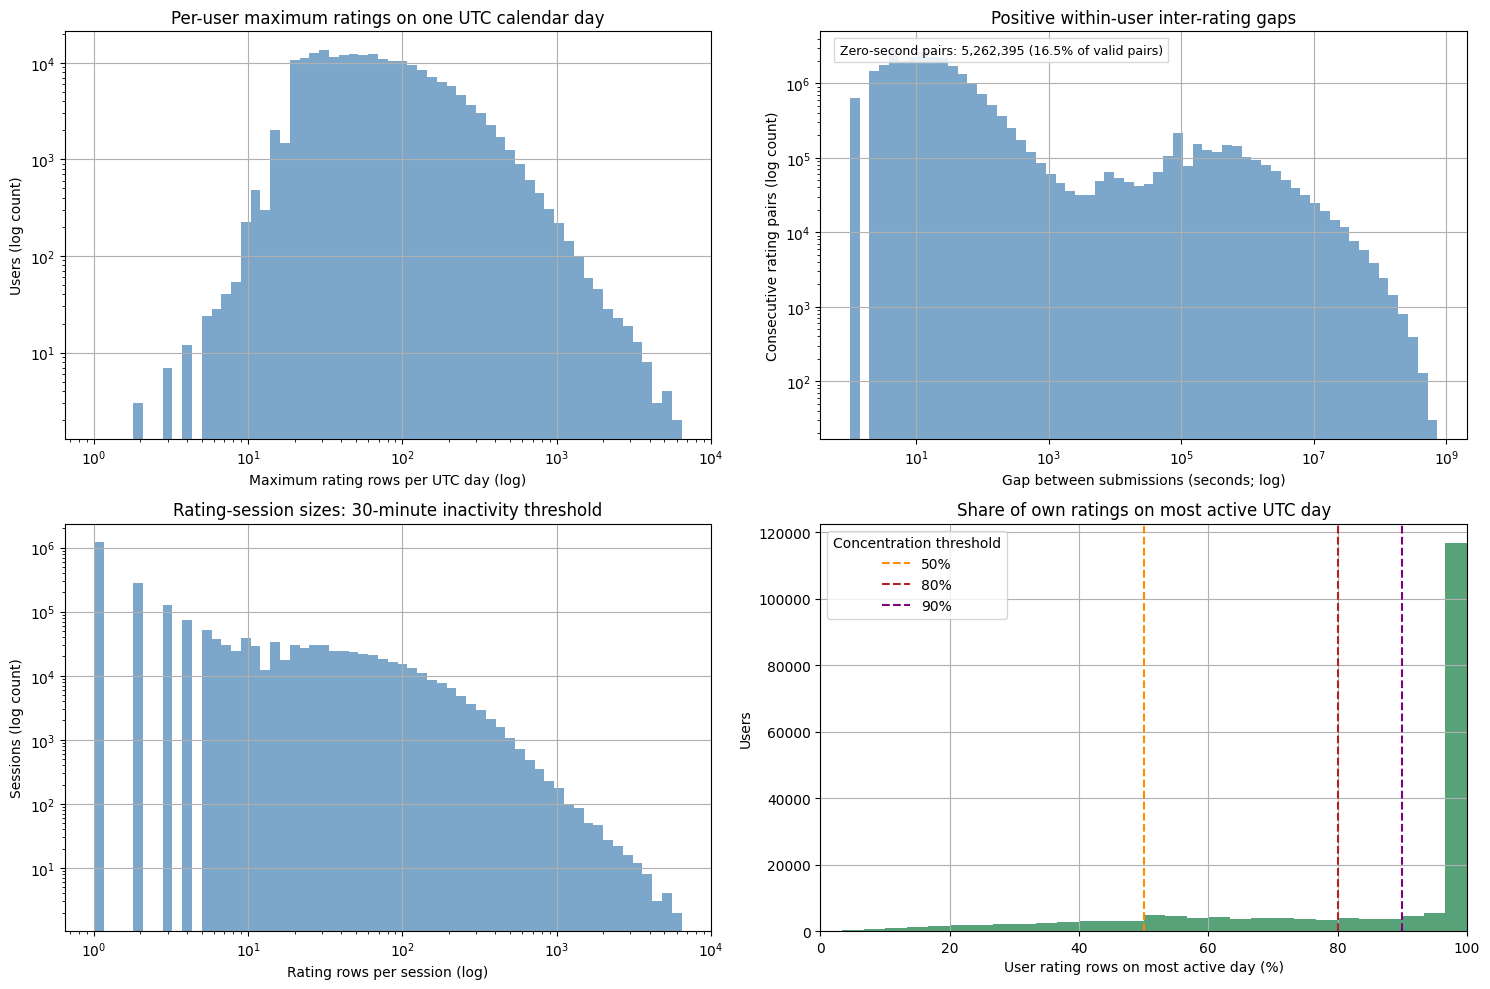

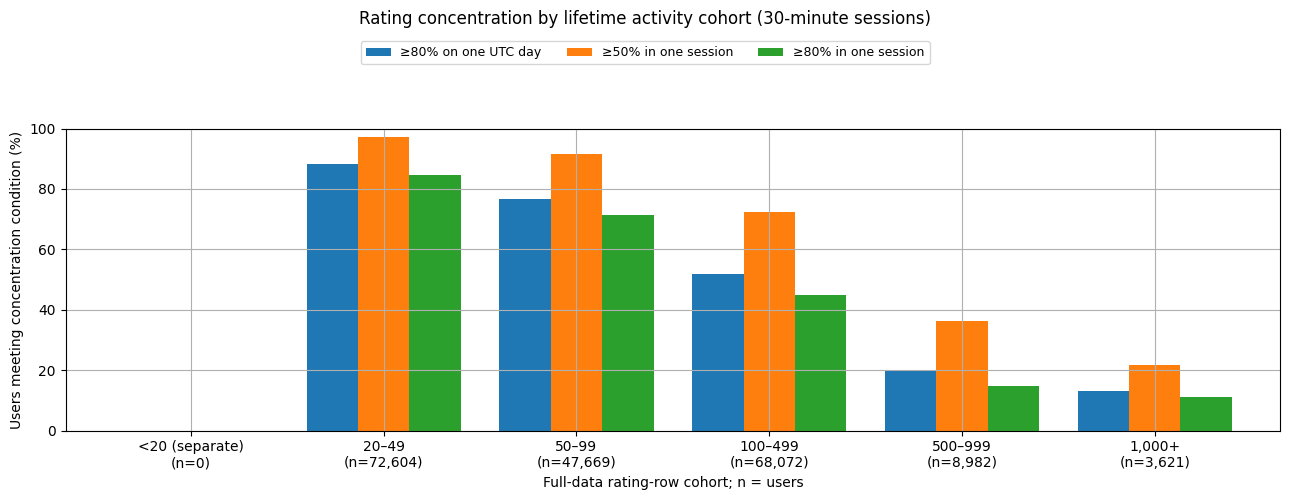

In [24]:
burst_distribution_fig, burst_axes = plt.subplots(2, 2, figsize=(15, 10))
for burst_axis, burst_histogram, burst_title, burst_xlabel, burst_ylabel in [
    (burst_axes[0, 0], _burst_log_histogram(burst_user_stats['max_ratings_in_utc_day'].to_numpy(), BURST_HISTOGRAM_BINS),
     'Per-user maximum ratings on one UTC calendar day', 'Maximum rating rows per UTC day (log)', 'Users'),
    (burst_axes[0, 1], burst_gap_histogram,
     'Positive within-user inter-rating gaps', 'Gap between submissions (seconds; log)', 'Consecutive rating pairs'),
    (burst_axes[1, 0], burst_default_sessions['histogram'],
     f'Rating-session sizes: {SESSION_GAP_MINUTES:g}-minute inactivity threshold', 'Rating rows per session (log)', 'Sessions'),
]:
    burst_counts, burst_edges = burst_histogram
    burst_axis.stairs(burst_counts, burst_edges, fill=True, alpha=.70, color='steelblue')
    burst_axis.set(xscale='log', title=burst_title, xlabel=burst_xlabel, ylabel=burst_ylabel)
    if np.any(burst_counts > 0):
        burst_axis.set_yscale('log')
        burst_axis.set_ylabel(burst_ylabel + ' (log count)')
    else:
        burst_axis.text(.5, .5, 'No positive gaps to plot', transform=burst_axis.transAxes, ha='center')
burst_zero_gap_row = burst_gap_thresholds.set_index('threshold').loc['Exactly 0 seconds']
burst_zero_annotation = (f'Zero-second pairs: {int(burst_zero_gap_row["consecutive_pairs"]):,} '
                         f'({burst_zero_gap_row["pct_of_valid_pairs"]:.1f}% of valid pairs)'
                         if burst_zero_gap_row['valid_within_user_pair_denominator'] else
                         'Zero-second pairs: 0 (no within-user pairs)')
burst_axes[0, 1].text(.03, .97, burst_zero_annotation, transform=burst_axes[0, 1].transAxes,
                      va='top', fontsize=9, bbox={'facecolor': 'white', 'alpha': .85, 'edgecolor': 'lightgray'})
burst_axes[1, 1].hist(burst_user_stats['pct_on_most_active_day'], bins=np.linspace(0, 100, 31),
                      color='seagreen', alpha=.8)
for burst_percentage, burst_color in [(50, 'darkorange'), (80, 'firebrick'), (90, 'purple')]:
    burst_axes[1, 1].axvline(burst_percentage, color=burst_color, linestyle='--', label=f'{burst_percentage}%')
burst_axes[1, 1].set(title='Share of own ratings on most active UTC day',
                      xlabel='User rating rows on most active day (%)', ylabel='Users', xlim=(0, 100))
burst_axes[1, 1].legend(title='Concentration threshold')
burst_distribution_fig.tight_layout()
plt.show()

burst_plot_columns = {
    'pct_users_at_least_80pct_on_one_utc_day': '≥80% on one UTC day',
    'pct_users_at_least_50pct_in_one_session': '≥50% in one session',
    'pct_users_at_least_80pct_in_one_session': '≥80% in one session',
}
burst_cohort_fig, burst_cohort_axis = plt.subplots(figsize=(13, 5))
burst_cohort_summary[list(burst_plot_columns)].rename(columns=burst_plot_columns).plot.bar(
    ax=burst_cohort_axis, rot=0, width=.8)
burst_cohort_axis.set_xticklabels([
    f'{label}\n(n={int(count):,})' for label, count in zip(burst_cohort_summary.index, burst_cohort_summary['users'])])
burst_cohort_axis.set(title=f'Rating concentration by lifetime activity cohort ({SESSION_GAP_MINUTES:g}-minute sessions)',
                     xlabel='Full-data rating-row cohort; n = users', ylabel='Users meeting concentration condition (%)', ylim=(0, 100))
burst_cohort_axis.set_title('')
burst_cohort_handles, burst_cohort_labels = burst_cohort_axis.get_legend_handles_labels()
burst_cohort_axis.get_legend().remove()
burst_cohort_fig.suptitle(
    f'Rating concentration by lifetime activity cohort ({SESSION_GAP_MINUTES:g}-minute sessions)', y=.99)
burst_cohort_fig.legend(burst_cohort_handles, burst_cohort_labels, loc='upper center',
                        bbox_to_anchor=(.5, .94), ncol=3, fontsize=9)
burst_cohort_fig.tight_layout(rect=(0, 0, 1, .86))
plt.show()


### Evidence-based implications for recommendation evaluation
**Objective:** connect the computed concentration measures to the prediction task without inferring unavailable watch logs.
The following discussion is generated from this section's results. It keeps temporal leakage, exposure/selection bias,
and uncertainty about consumption time separate. It does not approve a new split, alter an existing split study, or
claim that concentrated submissions necessarily represent retrospective ratings.


In [25]:
burst_gap_lookup = burst_gap_thresholds.set_index('threshold')
burst_user_count = len(burst_user_stats)
burst_high_day_pct = burst_concentration_summary.loc['at_least_80pct_on_one_utc_day', 'pct_of_users']
burst_high_session_pct = burst_concentration_summary.loc['at_least_80pct_in_one_session', 'pct_of_users']
burst_default_summary = burst_default_sessions['summary']
burst_pair_denominator = int(burst_gap_lookup['valid_within_user_pair_denominator'].iloc[0])
if burst_pair_denominator:
    burst_gap_evidence = (f'{burst_gap_lookup.loc["Within 60 seconds", "pct_of_valid_pairs"]:.1f}% of '
        f'{burst_pair_denominator:,} valid consecutive within-user pairs are at most 60 seconds apart; '
        f'{burst_gap_lookup.loc["Exactly 0 seconds", "pct_of_valid_pairs"]:.1f}% share a timestamp.')
else:
    burst_gap_evidence = 'No within-user consecutive pairs exist, so gap percentages are undefined.'
burst_discussion = (
    f'**Computed evidence:** among {burst_user_count:,} users, {burst_high_day_pct:.1f}% submitted at least 80% '
    f'of their observed ratings on one UTC calendar day, and {burst_high_session_pct:.1f}% submitted at least 80% '
    f'in one {SESSION_GAP_MINUTES:g}-minute-inactivity session. {burst_gap_evidence} '
    f'{burst_default_summary["pct_ratings_in_sessions_ge_20"]:.1f}% of rating rows belong to sessions of at least '
    f'20 rows. The median session duration is {burst_default_summary["median_session_duration_seconds"]:.0f} seconds; '
    'inspect the duration quantiles, inactivity-threshold sensitivity table, and cohort counts before generalizing.\n\n'
    '**Interpretation:** timestamps measure submissions. Concentrated submissions may be compatible with batch or '
    'retrospective rating, but they do not prove that explanation or identify independent viewing events. '
    'Rating-submission order does not necessarily identify movie-consumption order.\n\n'
    '- **Temporal leakage:** information from after an evaluation cutoff enters historical features, model fitting, or '
    'candidate construction. Bursts do not by themselves demonstrate this. A global cutoff through a submission session '
    'can split related labels, affecting task difficulty and dependence without automatically causing leakage. '
    'Keep identical timestamps together as the existing feasibility study does; a future session-boundary sensitivity '
    'study would need protocol approval.\n'
    '- **Exposure/selection bias:** observed ratings come from selected users and selected movies that users choose '
    'to rate. Missing ratings are not verified negative preferences; burst statistics do not reveal exposure or remove this bias.\n'
    '- **Uncertain consumption time:** even perfectly leakage-free splits cannot recover viewing dates or viewing order '
    'from submission timestamps alone. Impression and watch logs would be needed to study those events, repeated watches, '
    'and opportunity to consume.\n\n'
    '**Global chronological evaluation remains meaningful for predicting future observed rating submissions** when '
    'features, candidates, and fitting use only information available before each cutoff. It evaluates that task; '
    'it does not establish performance on a true sequence of movie consumption. No causal explanation, completed-watch '
    'claim, or revised train/validation/test allocation follows from these descriptive results alone.'
)
display(Markdown(burst_discussion))
# Release only arrays created in this appended section; never clear prior figures or existing EDA variables.
for burst_temporary_array in ('burst_sorted_timestamps', 'burst_inter_rating_gaps', 'burst_user_starts'):
    globals().pop(burst_temporary_array, None)


**Computed evidence:** among 200,948 users, 68.7% submitted at least 80% of their observed ratings on one UTC calendar day, and 63.6% submitted at least 80% in one 30-minute-inactivity session. 83.0% of 31,799,256 valid consecutive within-user pairs are at most 60 seconds apart; 16.5% share a timestamp. 83.9% of rating rows belong to sessions of at least 20 rows. The median session duration is 0 seconds; inspect the duration quantiles, inactivity-threshold sensitivity table, and cohort counts before generalizing.

**Interpretation:** timestamps measure submissions. Concentrated submissions may be compatible with batch or retrospective rating, but they do not prove that explanation or identify independent viewing events. Rating-submission order does not necessarily identify movie-consumption order.

- **Temporal leakage:** information from after an evaluation cutoff enters historical features, model fitting, or candidate construction. Bursts do not by themselves demonstrate this. A global cutoff through a submission session can split related labels, affecting task difficulty and dependence without automatically causing leakage. Keep identical timestamps together as the existing feasibility study does; a future session-boundary sensitivity study would need protocol approval.
- **Exposure/selection bias:** observed ratings come from selected users and selected movies that users choose to rate. Missing ratings are not verified negative preferences; burst statistics do not reveal exposure or remove this bias.
- **Uncertain consumption time:** even perfectly leakage-free splits cannot recover viewing dates or viewing order from submission timestamps alone. Impression and watch logs would be needed to study those events, repeated watches, and opportunity to consume.

**Global chronological evaluation remains meaningful for predicting future observed rating submissions** when features, candidates, and fitting use only information available before each cutoff. It evaluates that task; it does not establish performance on a true sequence of movie consumption. No causal explanation, completed-watch claim, or revised train/validation/test allocation follows from these descriptive results alone.